| Field | Value |
|---|---|
| Dataset | Credit Card Customer Churn (BankChurners) |
| Depth track | Classification Depth |
| Final model | Random Forest (n_estimators=100, default threshold 0.5) |
| Stratified dummy F1 / ROC AUC | 0.164 / 0.501 |
| Final model F1 / ROC AUC | 0.883 / 0.990 (5-fold CV mean) |
| Leakage columns dropped | Two Naive Bayes classifier output columns (pre-computed predictions of the same target, included in the original Kaggle file) |
| Full run time on Colab | 1 Minutes 37 Seconds |

In [1]:



# Data handling
import pandas as pd
import numpy as np
import sqlite3
import os

# Dataset download
import kagglehub

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

# Clustering
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Train/test split
from sklearn.model_selection import train_test_split

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    precision_recall_curve,
    roc_curve
)

# Cross Validation
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Stratified Dummy
from sklearn.dummy import DummyClassifier

In [2]:
import time
notebook_start = time.time()

In [3]:



%pip install -q kagglehub

Note: you may need to restart the kernel to use updated packages.


# PART 1

In [4]:
# Loading Dataset from Kaggke

path = kagglehub.dataset_download("sakshigoyal7/credit-card-customers")
print("Dataset downloaded to:", path)


csv_file = os.path.join(path, "BankChurners.csv")
df = pd.read_csv(csv_file)

Dataset downloaded to: C:\Users\hp\.cache\kagglehub\datasets\sakshigoyal7\credit-card-customers\versions\1


In [5]:
# Connect to Sqlite database
conn = sqlite3.connect("churn.db")
df.to_sql("churn_raw", conn, if_exists="replace", index=False)

10127

SQL QUERIES

In [6]:
# Confirm it's queryable with actual SQL

query = "SELECT * FROM churn_raw LIMIT 5;"
pd.read_sql_query(query, conn)

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


### Distribution of Card Category: (Query 1)

This is to count how many customer fall into each card tier (Blue/Gold/Plantinum/Silver) to confirm the class imbalance in the card category

FINDINGS:

The Blue card holders had the largest number, while platinum card holders has the least amount. Blue is roughly 470x of platinum, This is a big imbalance to take note of. This skewness also signals that the card category won't be a strong predictor of churn.

In [7]:
query = pd.read_sql_query("""
SELECT card_category, COUNT(*) AS count
FROM churn_raw
GROUP BY card_category
""", conn
)

print(query.shape)
query.head()

(4, 2)


,Card_Category,count
0,Blue,9436
1,Gold,116
2,Platinum,20
3,Silver,555


### Churn Rate By Card Tier: (Query 2)

Findings:

Churn rate is fairly consistent across card tiers, ranging from 14.8% (Silver) to 18.1% (Gold), with Blue the majority tier sitting in the middle at 16.1%. Platinum showed a notably higher rate (25%), but this is based on only 5 attrited customers out of 20 total Platinum holders, making it statistically unreliable, a single customer's status shifts that rate by 5 percentage points.

In [8]:
query = pd.read_sql_query("""
SELECT card_category, attrition_flag,
COUNT(*) AS count
FROM churn_raw
GROUP BY card_category, attrition_flag
""", conn
)

print(query.shape)
query.head(10)


(8, 3)


,Card_Category,Attrition_Flag,count
0,Blue,Attrited Customer,1519
1,Blue,Existing Customer,7917
2,Gold,Attrited Customer,21
3,Gold,Existing Customer,95
4,Platinum,Attrited Customer,5
5,Platinum,Existing Customer,15
6,Silver,Attrited Customer,82
7,Silver,Existing Customer,473


### Average Metrics By Churn Status (Query 3)

Findings:

Finding: Attrited customers show similar credit limits to existing customers (7% difference) but substantially lower transaction amounts (33% less) and transaction counts (35% fewer) over the past 12 months. Months inactive is also slightly higher for attrited customers.

Conclusion: Churn appears more strongly associated with declining card usage/engagement than with credit capacity; customers who churn aren't necessarily financially constrained, they're simply using the card less before leaving.

In [9]:
query = pd.read_sql_query("""
SELECT attrition_flag,
AVG(Credit_Limit) AS avg_credit_limit,
AVG(Total_Trans_Amt) AS avg_total_trans_amt,
AVG(Total_Trans_Ct) AS avg_total_trans_ct,
AVG(Months_Inactive_12_mon) AS avg_months_inactive_12_mon
FROM churn_raw
GROUP BY attrition_flag
""", conn
)

print(query.shape)
query.head(10)

(2, 5)


,Attrition_Flag,avg_credit_limit,avg_total_trans_amt,avg_total_trans_ct,avg_months_inactive_12_mon
0,Attrited Customer,8136.039459,3095.025814,44.933620,2.693301
1,Existing Customer,8726.877518,4654.655882,68.672588,2.273765


SQL QUERY SUMMARY:

* Card tier distribution: Blue is overwhelmingly the dominant tier (9,436 of 10,000 customers), with Silver, Gold, and Platinum making up small minorities: Platinum especially tiny at just 20 customers.
* Churn rate by tier: Churn rate is fairly flat across Blue (16.1%), Silver (14.8%), and Gold (18.1%). Platinum showed a higher rate (25%), but with only 5 attrited customers out of 20, this is not statistically reliable. Card_Category does not appear to be a meaningful standalone predictor of churn.
* Engagement metrics by churn status: Attrited and existing customers have similar credit limits (7% difference), but attrited customers show substantially lower transaction amounts (~33% less) and transaction counts (35% fewer) over 12 months, plus slightly higher months inactive. This points to declining engagement/usage not financial capacity as the stronger signal associated with churn.
* Overall takeaway: Card tier is a weak signal; transaction behavior (amount and frequency) is a much stronger candidate feature for predicting churn, and could inform an early-warning approach for the business (flagging customers whose usage is dropping before they fully churn).

## EXPLORATORY DATA ANALYSIS (EDA)

In [10]:
df.shape

(10127, 23)

Dataset Shape

We have 10,127 Rows and 23 Columns in the dataset

In [11]:
print(df.dtypes)

CLIENTNUM                                                                                                                               int64
Attrition_Flag                                                                                                                         object
Customer_Age                                                                                                                            int64
Gender                                                                                                                                 object
Dependent_count                                                                                                                         int64
Education_Level                                                                                                                        object
Marital_Status                                                                                                                         object
Income

In [12]:
# Select columns with explicit categorical dytype
categorical_columns = df.select_dtypes(include=['object']).columns

# Select columns with explicit numerical dytype
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

print("Categorical Columns:")
print(categorical_columns)

print("\nNumerical Columns:")
print(numerical_columns)

Categorical Columns:
Index(['Attrition_Flag', 'Gender', 'Education_Level', 'Marital_Status',
       'Income_Category', 'Card_Category'],
      dtype='object')

Numerical Columns:
Index(['CLIENTNUM', 'Customer_Age', 'Dependent_count', 'Months_on_book',
       'Total_Relationship_Count', 'Months_Inactive_12_mon',
       'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal',
       'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt',
       'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio',
       'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1',
       'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2'],
      dtype='object')


Missing Values: No missing Values were found

In [13]:
print(df.isnull().sum())

CLIENTNUM                                                                                                                             0
Attrition_Flag                                                                                                                        0
Customer_Age                                                                                                                          0
Gender                                                                                                                                0
Dependent_count                                                                                                                       0
Education_Level                                                                                                                       0
Marital_Status                                                                                                                        0
Income_Category                                 

In [14]:
# Duplicates

df.duplicated().sum()

np.int64(0)

Data Cleaning

In [15]:
[col for col in df.columns if 'Naive_Bayes' in col]

['Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1',
 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2']

In [16]:
df = df.drop(columns=[
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1',
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2'
])

These two columns are not original features of the credit card customer data. They are the pre-computed prediction outputs of a Naive Bayes classifier that the original dataset author ran and included in the file, as disclosed on the dataset's Kaggle page. Retaining them would constitute data leakage, since they are themselves predictions of the same target variable this project aims to predict, generated using a method and feature set outside this project's control. No other rows or columns were dropped: the dataset had no missing values requiring imputation or removal, and no duplicate rows were found. Categorical "Unknown" values in Education_Level, Marital_Status, and Income_Category were retained as a legitimate category rather than treated as missing data requiring cleaning, since discarding them would mean losing real information for a meaningful portion of customers.

Target Distribution

Target Column - Attrition Flag
Existing Customer" ≈ 84%, "Attrited Customer" ≈ 16%

In [17]:
# Frequency Counts
print(df['Attrition_Flag'].value_counts())

Attrition_Flag
Existing Customer    8500
Attrited Customer    1627
Name: count, dtype: int64


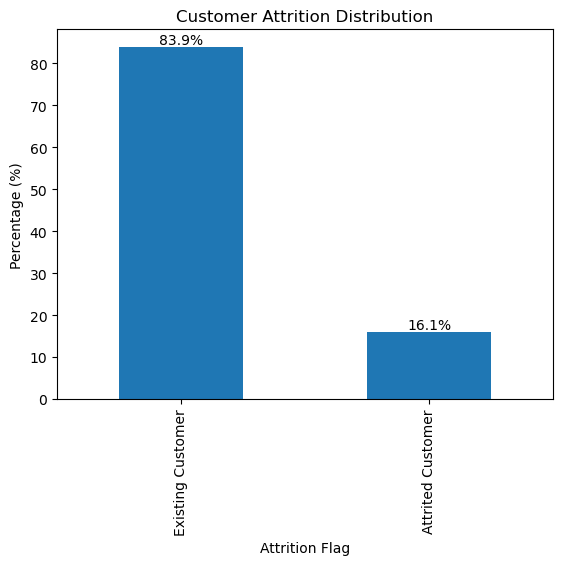

In [18]:
# Visualization of Target Distribution

# Calculate percentages
attrition_pct = df['Attrition_Flag'].value_counts(normalize=True) * 100
attrition_pct

# Create bar chart
ax = attrition_pct.plot(kind='bar')

# Add percentage labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%')

plt.ylabel('Percentage (%)')
plt.xlabel('Attrition Flag')
plt.title('Customer Attrition Distribution')
plt.show()

Feature Distribution

In [19]:
df['Total_Trans_Amt'].describe()

count    10127.000000
mean      4404.086304
std       3397.129254
min        510.000000
25%       2155.500000
50%       3899.000000
75%       4741.000000
max      18484.000000
Name: Total_Trans_Amt, dtype: float64

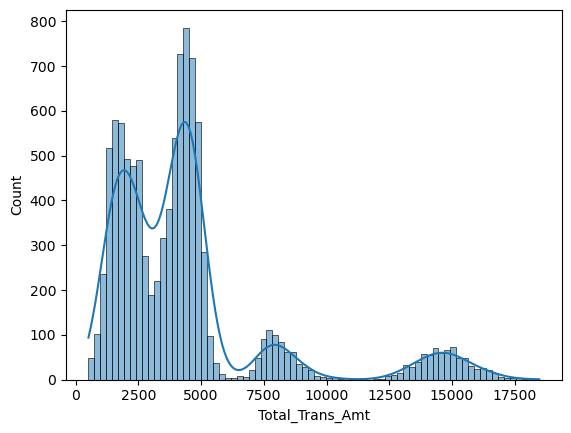

In [20]:
# Visualization

sns.histplot(df['Total_Trans_Amt'], kde=True)
plt.show()

 Finding

`Total_Trans_Amt` shows a **multimodal distribution** rather than a single smooth curve, with approximately three distinct customer groups:

1. Largest cluster — falls between roughly $1,000 and $5,500, peaking near $4,500.
   
2. Smaller cluster — appears between approximately $7,000 and $10,000.

   
3. Smallest cluster — follows between roughly $12,500 and $18,000.

There are relatively clear gaps between these ranges, with very few customers falling between the clusters.

---

 Conclusion

This pattern suggests that `Total_Trans_Amt` may not represent one uniform customer population. The gaps between the clusters could indicate **distinct underlying spending groups**, such as different spending tiers or customer segments, rather than one continuous range of spending behavior.

This finding is worth investigating further by checking whether the observed clusters align with other variables, such as `Total_Trans_Ct`, `Card_Category`, or `Income_Category`. Such comparisons may help determine whether differences in transaction frequency, card type, income level, or other customer characteristics help explain the spending bands.

---

 Modeling Consideration

The multimodal distribution should be considered during preprocessing and modeling. However, **non-normality alone does not make standard scaling methods inappropriate**. Instead, the distribution should be examined to determine whether a transformation, such as a logarithmic transformation, is useful for the selected model.

Tree-based models are generally less sensitive to the shape and scale of numerical features, while some distance-based or linear models may benefit more from appropriate transformation and scaling.

In [21]:
df['Total_Trans_Ct'].describe()

count    10127.000000
mean        64.858695
std         23.472570
min         10.000000
25%         45.000000
50%         67.000000
75%         81.000000
max        139.000000
Name: Total_Trans_Ct, dtype: float64

<Axes: xlabel='Total_Trans_Ct', ylabel='Count'>

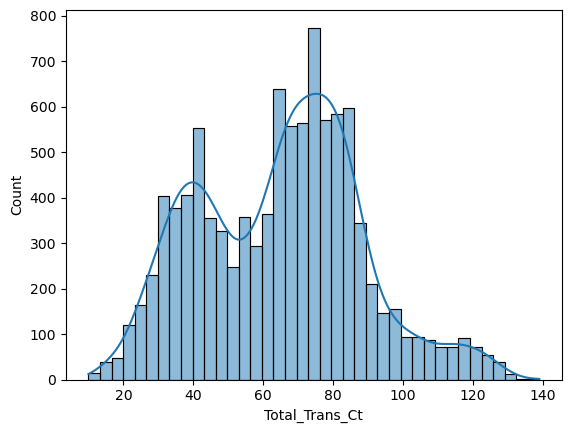

In [22]:
# Visualization

sns.histplot(df['Total_Trans_Ct'], kde=True)


 Finding

Unlike `Total_Trans_Amt`, `Total_Trans_Ct` shows a **roughly symmetric, unimodal distribution**, with no obvious clusters or gaps. This is consistent with its descriptive statistics, where the **mean (64.9)** and **median (67)** are relatively close, suggesting that the distribution is not strongly skewed.

 Conclusion

The contrast between these two related features suggests that the clustering observed in `Total_Trans_Amt` is **less likely to be explained by transaction frequency alone**. Instead, it may be more closely related to **differences in the average value of individual transactions**. This could indicate the presence of distinct **customer spending tiers**, rather than clearly separated groups based on transaction frequency.

This finding supports further investigation of **average transaction size**, which can help distinguish customers who make frequent smaller purchases from those who make fewer but larger purchases.


In [23]:
df['Income_Category'].value_counts()

Income_Category
Less than $40K    3561
$40K - $60K       1790
$80K - $120K      1535
$60K - $80K       1402
Unknown           1112
$120K +            727
Name: count, dtype: int64

In [24]:
df['Income_Category'].value_counts(normalize=True) * 100

Income_Category
Less than $40K    35.163425
$40K - $60K       17.675521
$80K - $120K      15.157500
$60K - $80K       13.844179
Unknown           10.980547
$120K +            7.178829
Name: proportion, dtype: float64

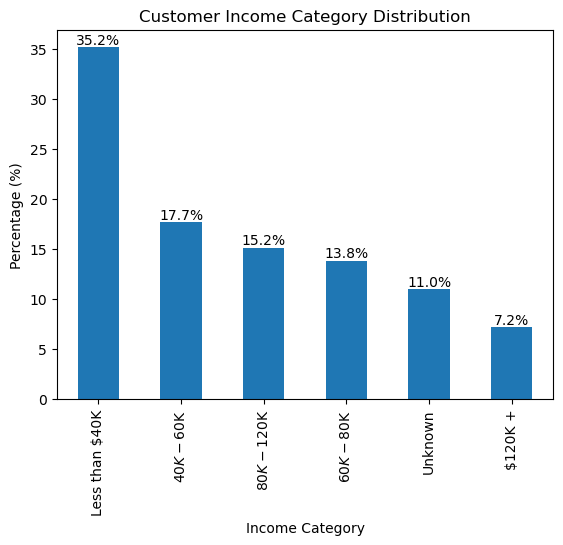

In [25]:
# Visualization

# Calculate percentages
income_pct = df['Income_Category'].value_counts(normalize=True) * 100
income_pct

# Create bar chart
ax = income_pct.plot(kind='bar')

# Add percentage labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%')

plt.ylabel('Percentage (%)')
plt.xlabel('Income Category')
plt.title('Customer Income Category Distribution')
plt.show()

 Income Category

**Findings:**
The income distribution is heavily skewed toward the lower income brackets. Approximately **35.2% of customers report an income of less than `$40K`**, with the percentage generally declining as income increases, reaching approximately **7.2% for the `$120K+` category**. However, there is also a sizeable `"Unknown"` category, which represents a larger proportion of customers than the highest income bracket.

**Conclusion:**
The concentration of customers in the lower income brackets is reasonable for a general customer base, where high-income customers are typically a smaller proportion of the population. However, the sizeable `"Unknown"` group should be addressed before modeling rather than ignored. Since `"Unknown"` represents missing information stored as a categorical value rather than a true null, potential approaches include **retaining it as a separate category, imputing the missing values, or evaluating whether excluding those records is appropriate**. The chosen approach should be assessed based on its potential impact on model performance and bias.


 Dataset Overview

The dataset contains **10,127 customer records**. Two irrelevant columns, which were leftover Naive Bayes classifier outputs from the original data source, were identified and dropped because they were not genuine features.

The dataset is largely clean; however, several categorical columns use `"Unknown"` as a value rather than a true null. This means that a standard missing-values check alone does not capture all incomplete data.

 Target Distribution

The target variable, `Attrition_Flag`, is **imbalanced**: approximately **84%** of customers are `"Existing Customer"`, while about **16%** are `"Attrited Customer"`.

This imbalance means that future modeling should rely on metrics such as **precision, recall, F1-score, and ROC-AUC** rather than plain accuracy. A model that always predicts `"Existing Customer"` would already appear highly accurate while providing little practical value for identifying customers at risk of churn.

 Card Category

`Card_Category` is heavily skewed toward the **Blue** tier, which contains **9,436 of 10,127 customers**. Silver, Gold, and especially Platinum customers make up much smaller groups, with only **20 Platinum customers**.

Churn rates across the card tiers were relatively similar, ranging from **14.8% for Silver** to **18.1% for Gold**, while Blue had a churn rate of approximately **16.1%**. Platinum showed a higher churn rate of **25%**, but this was based on only **5 attrited customers**, making the estimate statistically unreliable.

Overall, `Card_Category` does not appear to be a strong standalone predictor of churn.

 Engagement Metrics by Churn Status

Attrited and existing customers had relatively similar credit limits, with a difference of approximately **7%**. However, attrited customers showed substantially lower engagement, with approximately **33% lower total transaction amounts** and **35% fewer transactions** over the previous 12 months. They also had slightly more months of inactivity.

This suggests that churn may be more strongly associated with **declining customer engagement and card usage** than with financial capacity alone.

 `Total_Trans_Amt` — Total Transaction Amount

`Total_Trans_Amt` showed a **multimodal distribution** rather than a single smooth curve, with three distinct customer clusters:

* Approximately **$1,000–$5,500**
* Approximately **$7,000–$10,000**
* Approximately **$12,500–$18,000**

These groups are separated by noticeable gaps, suggesting the presence of distinct spending subgroups within the customer base rather than one continuous spending pattern.

This structure may warrant further investigation and potentially a transformation or additional feature engineering before modeling.

 `Total_Trans_Ct` — Total Transaction Count

Unlike transaction amount, `Total_Trans_Ct` showed a **roughly symmetric, unimodal distribution** with no obvious distinct clusters. This is consistent with its **mean of 64.9** and **median of 67**, which are relatively close.

The contrast between `Total_Trans_Amt` and `Total_Trans_Ct` suggests that the clustering observed in transaction amount may be more strongly influenced by **differences in spending per transaction** than by how frequently customers transact.

This observation also provides motivation for creating the `Avg_Trans_Size` feature.

 Income Category

The income distribution is skewed toward the lower income brackets. Approximately **35.2%** of customers report `"Less than $40K"`, while the percentages generally decline across the higher income categories, reaching **7.2%** for `"120K+"`.

The `"Unknown"` category accounts for approximately **11.0%** of customers, which is larger than the highest reported income bracket itself.

Therefore, `Income_Category` will require a clearly defined **missing/unknown-value handling strategy** before being used in the modeling stage.


 Part 1: Data Foundation — Shape, Types, Missing Values, and Cleaning

 Shape

The raw dataset, loaded from Kaggle, contains **10,127 rows and 23 columns**.

 Data Types

Columns fall into three groups:

- **Numeric integer columns** — e.g., `Customer_Age`, `Months_on_book`, `Total_Trans_Amt`
- **Numeric float columns** — e.g., `Credit_Limit`, `Avg_Utilization_Ratio`
- **Object (text/categorical) columns** — `Attrition_Flag`, `Gender`, `Education_Level`, `Marital_Status`, `Income_Category`, `Card_Category`

Two additional float columns were present at load time — leftover outputs from a Naive Bayes classifier run by the original dataset author, not genuine features of the data (see **Data Cleaning** below).

 Missing Values

A full null check (`df.isnull().sum()`) confirmed **zero missing values across all 23 columns**.

However, several categorical columns (`Education_Level`, `Marital_Status`, `Income_Category`) contain an explicit `"Unknown"` string value rather than a true null. This was treated as a deliberate, meaningful category throughout the project (addressed directly in the Feature Engineering and Encoding section) rather than as missing data to be imputed or dropped, since discarding it would mean losing real information for 10–15% of customers in each affected column.

 Duplicates

A full-row duplicate check (`df.duplicated().sum()`) confirmed **zero duplicate rows** in the dataset.

 Target Distribution

The target variable, `Attrition_Flag`, is imbalanced:

| Class | Count | Percentage |
|---|---|---|
| Existing Customer | 8,500 | 83.9% |
| Attrited Customer | 1,627 | 16.1% |

This imbalance is addressed directly in Part 5.

 Data Cleaning

The only cleaning action applied to the raw dataset was dropping two columns:

- `Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1`
- `Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2`

**Justification:** These two columns are not original features of the credit card customer data. They are the pre-computed prediction outputs of a Naive Bayes classifier that the original dataset author ran and included in the file, as disclosed on the dataset's Kaggle page. Retaining them would constitute **data leakage**, since they are themselves predictions of the same target variable this project aims to predict, generated using a method and feature set outside this project's control.

No other rows or columns were dropped: the dataset had no missing values requiring imputation or removal, no duplicate rows, and no blanket `fillna()` was applied, since no column required it. Categorical `"Unknown"` values were retained as a legitimate category rather than treated as missing data requiring cleaning (see Encoding section for full reasoning).

# PART 2 - Feature Engineering and Encoding

Business Reasoning — Average Transaction Size

`Total_Trans_Amt` and `Total_Trans_Ct` each capture only part of a customer's spending behavior. **Average transaction size**, calculated as `Total_Trans_Amt` divided by `Total_Trans_Ct`, provides additional insight into the nature of that spending.

Customers who make **frequent, smaller purchases** are likely using the card as part of their regular spending routine, such as for groceries and other daily expenses. This type of consistent usage may indicate stronger habitual engagement with the card and potentially lower churn risk.

In contrast, customers who make **infrequent, larger purchases** may use the card primarily for occasional big-ticket expenses. Longer gaps between transactions may indicate a weaker day-to-day relationship with the card, potentially making these customers more susceptible to churn.


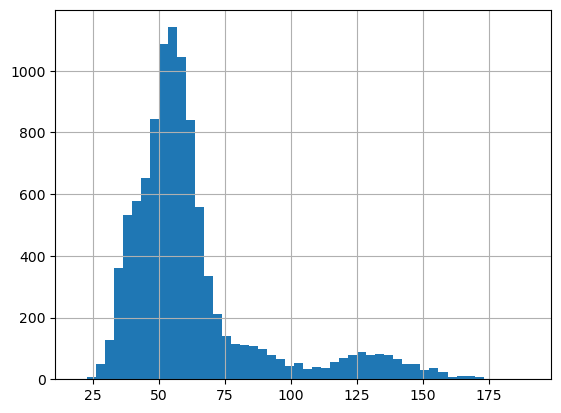

In [26]:
df['Avg_Trans_Size'] = df['Total_Trans_Amt'] / df['Total_Trans_Ct']
df['Avg_Trans_Size'].hist(bins=50)
plt.show()

Business Reasoning — Age Group

`Customer_Age` is treated as a continuous numerical variable, but customers at different life stages may have different financial priorities and card usage patterns.

Younger customers may prioritize different spending needs compared with older, more established customers. Additionally, financial behavior may shift at certain life-stage thresholds rather than changing smoothly with each additional year of age.

Binning age into groups may therefore help capture these **life-stage-driven differences** in customer engagement and churn risk more effectively than using raw age alone.


In [27]:
df['Customer_Age'].describe()

count    10127.000000
mean        46.325960
std          8.016814
min         26.000000
25%         41.000000
50%         46.000000
75%         52.000000
max         73.000000
Name: Customer_Age, dtype: float64

In [28]:
bins = [0, 35, 50, 65, 100]
labels = ['Early Career', 'Established/Mid-Career', 'Pre-Retirement', 'Retirement Age']

df['Age_Group'] = pd.cut(df['Customer_Age'], bins=bins, labels=labels, right=False)

print(df)

       CLIENTNUM     Attrition_Flag  Customer_Age Gender  Dependent_count  \
0      768805383  Existing Customer            45      M                3   
1      818770008  Existing Customer            49      F                5   
2      713982108  Existing Customer            51      M                3   
3      769911858  Existing Customer            40      F                4   
4      709106358  Existing Customer            40      M                3   
...          ...                ...           ...    ...              ...   
10122  772366833  Existing Customer            50      M                2   
10123  710638233  Attrited Customer            41      M                2   
10124  716506083  Attrited Customer            44      F                1   
10125  717406983  Attrited Customer            30      M                2   
10126  714337233  Attrited Customer            43      F                2   

      Education_Level Marital_Status Income_Category Card_Category  \
0    

In [29]:
df['Age_Group'].unique()

['Established/Mid-Career', 'Pre-Retirement', 'Early Career', 'Retirement Age']
Categories (4, object): ['Early Career' < 'Established/Mid-Career' < 'Pre-Retirement' < 'Retirement Age']

In [30]:
df['Age_Group'].value_counts()

Age_Group
Established/Mid-Career    5862
Pre-Retirement            3419
Early Career               735
Retirement Age             111
Name: count, dtype: int64

 Business Reasoning — Relationship-to-Contact Ratio

`Total_Relationship_Count` and `Contacts_Count_12_mon` each tell only part of a customer's relationship with the bank. `Total_Relationship_Count` reflects how invested a customer is, based on the number of products or accounts they hold. Meanwhile, `Contacts_Count_12_mon`, given that this customer base is dominated by standard retail card holders rather than business users, likely reflects customer friction or dissatisfaction rather than high-value engagement.

A customer with a **low relationship count and high contact count** may be both loosely tied to the bank and experiencing frustration, making them a potentially higher churn risk. In contrast, a customer with a **high relationship count and high contact count** is more deeply embedded across multiple products. This stronger relationship may cushion against churn even amid friction because switching banks would be more disruptive for them.

Combining these two columns into a single feature may therefore capture this **risk dynamic** more effectively than either column alone. The ratio provides a way to represent the customer's level of relationship with the bank relative to their level of contact or potential friction.


In [31]:
df['Relationship_Contact_Ratio'] = df['Total_Relationship_Count'] / (df['Contacts_Count_12_mon'] + 1)

df['Relationship_Contact_Ratio'].describe()

count    10127.000000
mean         1.271083
std          0.875351
min          0.142857
25%          0.750000
50%          1.000000
75%          1.500000
max          6.000000
Name: Relationship_Contact_Ratio, dtype: float64

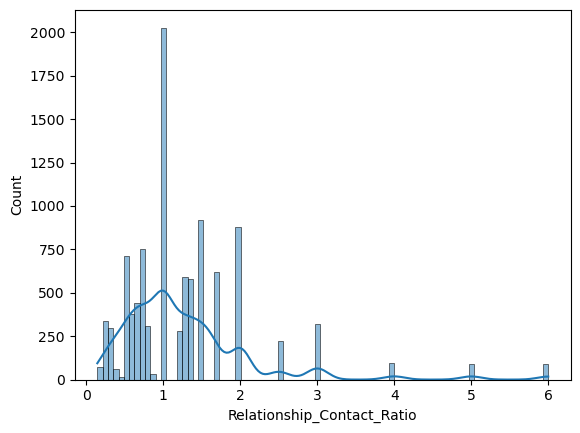

In [32]:
sns.histplot(df['Relationship_Contact_Ratio'], kde=True)
plt.show()

 Feature Engineering Summary


Feature Engineering

Three new features were created to capture patterns in customer behavior that the raw columns do not fully expose on their own. Each feature is grounded in a business hypothesis about churn risk and informed by patterns identified during EDA.

 1. Average Transaction Size (`Avg_Trans_Size`)

**Formula:**

```text
Avg_Trans_Size = Total_Trans_Amt / Total_Trans_Ct
```

**Business Reasoning:**

`Total_Trans_Amt` and `Total_Trans_Ct` each capture only part of a customer's spending behavior. A customer could transact frequently in small amounts or rarely in large amounts and still arrive at similar totals, yet these represent very different relationships with the card.

Average transaction size reveals this distinction. Customers making frequent, smaller purchases likely use the card as part of their daily routine, suggesting habitual engagement and potentially lower churn risk. Customers making infrequent, large purchases may have a weaker day-to-day relationship with the card, with longer gaps between uses, indicating potentially higher churn risk.

This feature is safe to compute directly because `Total_Trans_Ct` has a minimum value of 10 in this dataset, meaning there is no risk of division by zero.

---

 2. Age Group (`Age_Group`)

**Formula:**

```text
Age_Group = Binned Customer_Age using [0, 35, 50, 65, 100]
```

The resulting groups are:

* `Early Career`
* `Established/Mid-Career`
* `Pre-Retirement`
* `Retirement Age`

**Business Reasoning:**

`Customer_Age` is a continuous variable, but financial priorities and spending behavior may shift at life-stage thresholds rather than changing smoothly with each additional year. Younger customers may have different spending needs and financial priorities compared with older, more established customers.

Binning age into life-stage groups may therefore capture threshold effects on customer engagement and churn risk more effectively than raw age alone.

The bin boundaries were chosen based on general career and life-stage transitions and were checked against the actual distribution of `Customer_Age` (minimum = 26, maximum = 73, median = 46) to ensure that no group was left empty. The resulting groups range from 111 customers in the `Retirement Age` group to 5,862 customers in the `Established/Mid-Career` group.

---

 3. Relationship-to-Contact Ratio (`Relationship_Contact_Ratio`)

**Formula:**

```text
Relationship_Contact_Ratio = Total_Relationship_Count / (Contacts_Count_12_mon + 1)
```

**Business Reasoning:**

`Total_Relationship_Count` reflects how invested a customer is in the bank, based on the number of products or accounts they hold. In this customer base, which is dominated by standard retail card holders rather than business users, `Contacts_Count_12_mon` more plausibly reflects customer friction or potential dissatisfaction than high-value engagement.

A customer with a **low relationship count and high contact count** is both loosely tied to the bank and potentially experiencing frustration, suggesting higher churn risk. In contrast, a customer with a **high relationship count and high contact count** is more deeply embedded across multiple products. This stronger relationship may cushion against churn because switching banks would be more disruptive.

Division was used rather than addition, subtraction, or averaging because the ratio captures the **relative size of customer investment compared with customer friction**, rather than their combined magnitude. This is consistent with the same reasoning used for `Avg_Trans_Size`.

A constant of `1` was added to the denominator to safely handle customers with zero contacts in the previous 12 months, which is the observed minimum in the dataset. This avoids division by zero while preserving the intended ordering of the ratio.


ENCODING

Label/Ordinal Encoding

Educational Level

In [33]:
df['Education_Level'].unique()

array(['High School', 'Graduate', 'Uneducated', 'Unknown', 'College',
       'Post-Graduate', 'Doctorate'], dtype=object)

In [34]:
enc = OrdinalEncoder(categories=[['Unknown', 'Uneducated', 'High School', 'College', 'Graduate', 'Post-Graduate', 'Doctorate']])
df['Education_Level'] = enc.fit_transform(df[['Education_Level']])

In [35]:
df['Education_Level'].dtype


dtype('float64')

In [36]:
df['Education_Level'].value_counts()

Education_Level
4.0    3128
2.0    2013
0.0    1519
1.0    1487
3.0    1013
5.0     516
6.0     451
Name: count, dtype: int64

In [37]:
df['Education_Level'].head()

0    2.0
1    4.0
2    4.0
3    2.0
4    1.0
Name: Education_Level, dtype: float64

INCOME CATEGORY

In [38]:
df['Income_Category'].unique()

array(['$60K - $80K', 'Less than $40K', '$80K - $120K', '$40K - $60K',
       '$120K +', 'Unknown'], dtype=object)

In [39]:
enc = OrdinalEncoder(categories=[['Unknown', 'Less than $40K', '$40K - $60K', '$60K - $80K', '$80K - $120K', '$120K +']])
df['Income_Category'] = enc.fit_transform(df[['Income_Category']])

In [40]:
df['Income_Category'].dtype

dtype('float64')

In [41]:
df['Income_Category'].value_counts()

Income_Category
1.0    3561
2.0    1790
4.0    1535
3.0    1402
0.0    1112
5.0     727
Name: count, dtype: int64

AGE GROUP

In [42]:
df['Age_Group'].unique()

['Established/Mid-Career', 'Pre-Retirement', 'Early Career', 'Retirement Age']
Categories (4, object): ['Early Career' < 'Established/Mid-Career' < 'Pre-Retirement' < 'Retirement Age']

In [43]:
enc = OrdinalEncoder(categories=[['Early Career', 'Established/Mid-Career', 'Pre-Retirement', 'Retirement Age']])
df['Age_Group'] = enc.fit_transform(df[['Age_Group']])

In [44]:
df['Age_Group'].dtypes

dtype('float64')

In [45]:
df['Age_Group'].value_counts()

Age_Group
1.0    5862
2.0    3419
0.0     735
3.0     111
Name: count, dtype: int64

 Encoding: Ordinal (Label) Encoding

Three categorical columns were identified as having a genuine, meaningful order, making them candidates for ordinal encoding rather than one-hot encoding. Each was encoded using `sklearn.preprocessing.OrdinalEncoder` with a manually specified category order, rather than allowing the encoder to infer an order automatically, to ensure the assigned integers correctly reflect real-world rank.

 1. Education_Level

**Order used:** Unknown, Uneducated, High School, College, Graduate, Post-Graduate, Doctorate (0–6)

**Justification:** Education level has a natural, widely recognized hierarchy, from no formal education through increasingly advanced degrees. Assigning integers that follow this order allows the model to recognize that Doctorate represents more educational attainment than High School, a relationship one-hot encoding would discard.

 2. Income_Category

**Order used:** Unknown, Less than $40K, $40K–$60K, $60K–$80K, $80K–$120K, $120K+ (0–5)

**Justification:** Income brackets have a clear ascending order by dollar value, and preserving this order allows the model to interpret higher-income customers as genuinely "higher" on the scale rather than as unrelated, disconnected categories.

 3. Age_Group

**Order used:** Early Career, Established/Mid-Career, Pre-Retirement, Retirement Age (0–3)

**Justification:** This feature was engineered specifically to represent life-stage progression, so its ordinal structure follows directly from how it was constructed from `Customer_Age`. No "Unknown" category exists here, since `Age_Group` was derived from a fully populated numeric column with no missing values.

 Limitation — "Unknown" Placement

For `Education_Level` and `Income_Category`, "Unknown" was placed at the lowest position in the order rather than removed, since roughly 11–15% of customers fall into this category in each column and discarding it would mean losing real information. However, this placement implicitly tells the model that "Unknown" ranks below the lowest real category (e.g., below "Uneducated" or "Less than $40K"), which is not literally true — it simply means the value was not reported.

A more rigorous alternative would be to split each column into:

- A **binary flag** (e.g., `Income_Unknown`) marking whether the value was missing, combined with
- A **neutral placeholder** (such as the median bracket) in the ordinal column itself,

since missingness in income or education disclosure may itself carry predictive signal.

This project uses the simpler placement approach as a defensible first-pass choice, with the flag-based alternative noted as a follow-up experiment: once a baseline model is trained, both encoding strategies could be compared using validation AUC/PR to determine which better serves the final model.m

 One-Hot Encoding

In [46]:
df['Marital_Status'].unique()

array(['Married', 'Single', 'Unknown', 'Divorced'], dtype=object)

In [47]:
df['Gender'].unique()

array(['M', 'F'], dtype=object)

In [48]:
df['Card_Category'].unique()

array(['Blue', 'Gold', 'Silver', 'Platinum'], dtype=object)

In [49]:
df = pd.get_dummies(df, columns=['Gender', 'Marital_Status', 'Card_Category'], drop_first=True)

In [50]:
df.dtypes

CLIENTNUM                       int64
Attrition_Flag                 object
Customer_Age                    int64
Dependent_count                 int64
Education_Level               float64
Income_Category               float64
Months_on_book                  int64
Total_Relationship_Count        int64
Months_Inactive_12_mon          int64
Contacts_Count_12_mon           int64
Credit_Limit                  float64
Total_Revolving_Bal             int64
Avg_Open_To_Buy               float64
Total_Amt_Chng_Q4_Q1          float64
Total_Trans_Amt                 int64
Total_Trans_Ct                  int64
Total_Ct_Chng_Q4_Q1           float64
Avg_Utilization_Ratio         float64
Avg_Trans_Size                float64
Age_Group                     float64
Relationship_Contact_Ratio    float64
Gender_M                         bool
Marital_Status_Married           bool
Marital_Status_Single            bool
Marital_Status_Unknown           bool
Card_Category_Gold               bool
Card_Categor

In [51]:
df.head()

,CLIENTNUM,Attrition_Flag,Customer_Age,Dependent_count,Education_Level,Income_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,...,Avg_Trans_Size,Age_Group,Relationship_Contact_Ratio,Gender_M,Marital_Status_Married,Marital_Status_Single,Marital_Status_Unknown,Card_Category_Gold,Card_Category_Platinum,Card_Category_Silver
0,768805383,Existing Customer,45,3,2.0,3.0,39,5,1,3,...,27.238095,1.0,1.25,True,True,False,False,False,False,False
1,818770008,Existing Customer,49,5,4.0,1.0,44,6,1,2,...,39.121212,1.0,2.00,False,False,True,False,False,False,False
2,713982108,Existing Customer,51,3,4.0,4.0,36,4,1,0,...,94.350000,2.0,4.00,True,True,False,False,False,False,False
3,769911858,Existing Customer,40,4,2.0,1.0,34,3,4,1,...,58.550000,1.0,1.50,False,False,False,True,False,False,False
4,709106358,Existing Customer,40,3,1.0,3.0,21,5,1,0,...,29.142857,1.0,5.00,True,True,False,False,False,False,False


Feature Scaling

In [52]:
feature_columns = [
    'Customer_Age',
    'Dependent_count',
    'Months_on_book',
    'Total_Relationship_Count',
    'Months_Inactive_12_mon',
    'Contacts_Count_12_mon',
    'Credit_Limit',
    'Total_Revolving_Bal',
    'Avg_Open_To_Buy',
    'Total_Amt_Chng_Q4_Q1',
    'Total_Trans_Amt',
    'Total_Trans_Ct',
    'Total_Ct_Chng_Q4_Q1',
    'Avg_Utilization_Ratio',
    'Avg_Trans_Size',
    'Relationship_Contact_Ratio'
]

# 1. Select raw features
features = df[feature_columns]

# 2. Scale
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

# 3. Put scaled values back into df
scaled_df = pd.DataFrame(scaled_features, columns=feature_columns, index=features.index)
df[feature_columns] = scaled_df

# 4. Refresh features so it reflects the scaled values
features = df[feature_columns]

In [53]:
features.describe()

,Customer_Age,Dependent_count,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Avg_Trans_Size,Relationship_Contact_Ratio
count,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04,1.012700e+04
mean,1.361166e-16,-8.419584e-17,-3.437997e-16,-4.490445e-17,1.571656e-16,-7.858279e-17,1.234872e-16,-8.419584e-17,3.367834e-17,-1.347133e-16,-4.490445e-17,-1.796178e-16,1.571656e-16,1.010350e-16,-8.980890e-17,7.858279e-17
std,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00,1.000049e+00
min,-2.535541e+00,-1.806378e+00,-2.871068e+00,-1.809512e+00,-2.316674e+00,-2.219655e+00,-7.915266e-01,-1.426858e+00,-8.213361e-01,-3.466947e+00,-1.146344e+00,-2.337256e+00,-2.991597e+00,-9.971550e-01,-1.646592e+00,-1.288947e+00
25%,-6.643815e-01,-1.036462e+00,-6.171294e-01,-5.227845e-01,-3.375979e-01,-4.116160e-01,-6.686548e-01,-9.863389e-01,-6.759604e-01,-5.882438e-01,-6.619405e-01,-8.460801e-01,-5.469820e-01,-9.137243e-01,-5.718367e-01,-5.953137e-01
50%,-4.066159e-02,-2.665471e-01,8.964513e-03,1.205790e-01,-3.375979e-01,-4.116160e-01,-4.492525e-01,1.388875e-01,-4.394979e-01,-1.092203e-01,-1.486877e-01,9.123036e-02,-4.293775e-02,-3.587287e-01,-2.582234e-01,-3.096999e-01
75%,7.078024e-01,5.033681e-01,5.098397e-01,7.639426e-01,6.519402e-01,4.924038e-01,2.679862e-01,7.622408e-01,2.629041e-01,4.519214e-01,9.918090e-02,6.877007e-01,4.443050e-01,8.274384e-01,1.084713e-01,2.615278e-01
max,3.327426e+00,2.043199e+00,2.513340e+00,1.407306e+00,3.620555e+00,3.204463e+00,2.848054e+00,1.661686e+00,2.975375e+00,1.203060e+01,4.144855e+00,3.158792e+00,1.260857e+01,2.626640e+00,4.832064e+00,5.402577e+00


**Feature Scaling: StandardScaler**

Sixteen continuous numeric features (including the two engineered ratio features, Avg_Trans_Size and Relationship_Contact_Ratio) were scaled using sklearn.preprocessing.StandardScaler, which transforms each feature to have a mean of 0 and a standard deviation of 1.

**Justification**: StandardScaler was chosen over MinMaxScaler primarily because of the outlier sensitivity and skewed distributions observed during EDA. Total_Trans_Amt, for example, showed a multimodal distribution with values ranging from 510 to 18,484, clustered into distinct groups rather than spread evenly. Credit_Limit similarly showed a wide range and skew. MinMaxScaler compresses all values into a fixed 0-1 range based on the column's actual minimum and maximum, meaning a small number of extreme values at the high end would compress the bulk of "normal" values into a narrow sliver near 0, reducing the meaningful variation between typical customers. StandardScaler, by contrast, scales based on the mean and standard deviation, making it considerably less sensitive to extreme values at either end of the distribution. Given that several features in this dataset showed wide spreads and non-normal shapes rather than tight, bounded ranges, StandardScaler preserves the relative differences between customers more reliably than MinMaxScaler would.

Ordinal-encoded columns (Education_Level, Income_Category, Age_Group) and one-hot encoded binary columns (Gender_M, Marital_Status_*, Card_Category_*) were intentionally excluded from scaling, since they are already on small, meaningful integer or binary scales, and scaling them would not add value while potentially reducing their interpretability.

# PART 3 - CLUSTERING ANALYSIS

CLUSTERING ANALYSIS

K MEANS

In [54]:
inertias = []
silhouette_scores = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(features)
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(features, model.labels_))


In [55]:
print("Inertia (Within-Cluster Sum of Squares):")
print(inertias)
print("\nSilhouette Scores:")
print(silhouette_scores)

Inertia (Within-Cluster Sum of Squares):
[139915.02111817925, 125569.31641184233, 116269.08870941302, 109750.53944685767, 103376.57948150358, 98790.79016073387, 95924.7417293808, 92367.14521921474, 90419.48429094278]

Silhouette Scores:
[0.2235745589859432, 0.1304964592206487, 0.12742908020561888, 0.11805768407141393, 0.12419244828056786, 0.12772683181306316, 0.10897939932209086, 0.11289913406707476, 0.10689930308278807]


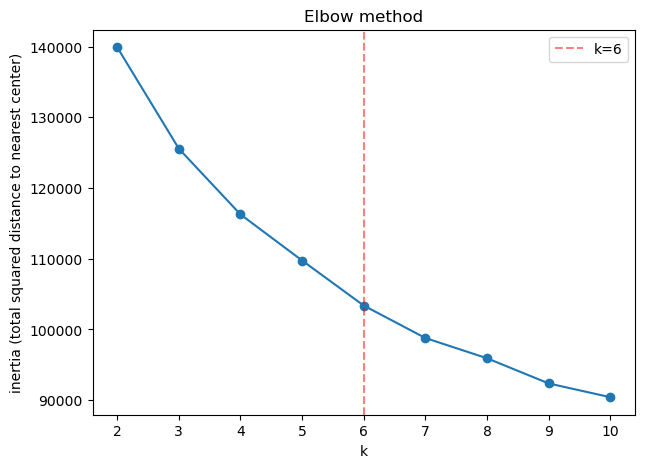

In [56]:
plt.figure(figsize=(7, 5))
plt.plot(range(2, 11), inertias, marker='o')
plt.axvline(6, color='red', linestyle='--', alpha=0.5, label='k=6')
plt.xlabel("k")
plt.ylabel("inertia (total squared distance to nearest center)")
plt.title("Elbow method")
plt.legend()
plt.show()

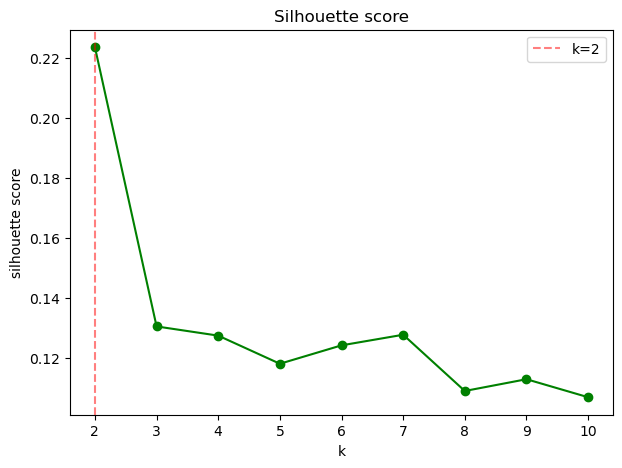

In [57]:
plt.figure(figsize=(7, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o', color='green')
plt.axvline(2, color='red', linestyle='--', alpha=0.5, label='k=2')
plt.xlabel("k")
plt.ylabel("silhouette score")
plt.title("Silhouette score")
plt.legend()
plt.show()

In [58]:
# Recover the original values from the scaled data
original_features = scaler.inverse_transform(df[feature_columns])

# Convert back to a DataFrame
original_df = pd.DataFrame(
    original_features,
    columns=feature_columns,
    index=df.index
)



In [59]:
original_df.describe()

,Customer_Age,Dependent_count,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Avg_Trans_Size,Relationship_Contact_Ratio
count,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000
mean,46.325960,2.346203,35.928409,3.812580,2.341167,2.455317,8631.953698,1162.814061,7469.139637,0.759941,4404.086304,64.858695,0.712222,0.274894,62.612717,1.271083
std,8.016814,1.298908,7.986416,1.554408,1.010622,1.106225,9088.776650,814.987335,9090.685324,0.219207,3397.129254,23.472570,0.238086,0.275691,26.404198,0.875351
min,26.000000,0.000000,13.000000,1.000000,0.000000,0.000000,1438.300000,0.000000,3.000000,0.000000,510.000000,10.000000,0.000000,0.000000,19.137931,0.142857
25%,41.000000,1.000000,31.000000,3.000000,2.000000,2.000000,2555.000000,359.000000,1324.500000,0.631000,2155.500000,45.000000,0.582000,0.023000,47.514573,0.750000
50%,46.000000,2.000000,36.000000,4.000000,2.000000,2.000000,4549.000000,1276.000000,3474.000000,0.736000,3899.000000,67.000000,0.702000,0.176000,55.794872,1.000000
75%,52.000000,3.000000,40.000000,5.000000,3.000000,3.000000,11067.500000,1784.000000,9859.000000,0.859000,4741.000000,81.000000,0.818000,0.503000,65.476673,1.500000
max,73.000000,5.000000,56.000000,6.000000,6.000000,6.000000,34516.000000,2517.000000,34516.000000,3.397000,18484.000000,139.000000,3.714000,0.999000,190.193182,6.000000


In [60]:
k = 6

Kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
Kmeans.fit(features)

original_df['Cluster'] = Kmeans.labels_


In [61]:
original_df['Cluster'].value_counts()

Cluster
5    2764
1    2451
2    1789
3    1189
4    1147
0     787
Name: count, dtype: int64

In [62]:
# grouping by

original_df.groupby('Cluster').mean()

,Customer_Age,Dependent_count,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Avg_Trans_Size,Relationship_Contact_Ratio
Cluster,,,,,,,,,,,,,,,,
0,46.454892,2.487929,36.036849,5.006353,2.270648,0.569250,6829.371156,1213.198221,5616.172935,0.789361,3535.557814,62.922490,0.769685,0.302296,55.120415,3.494282
1,44.287638,2.572011,34.224806,3.790698,2.409629,2.771522,5909.753284,305.202366,5604.550918,0.707387,3199.636067,58.047736,0.639083,0.049583,54.376682,1.067903
2,56.223030,1.342091,44.854667,4.136389,2.439911,2.670766,5243.708552,1380.131358,3863.577194,0.750058,3015.955282,55.468977,0.706816,0.374867,52.885069,1.193674
3,46.357443,2.592094,35.929352,3.899075,2.328007,2.656013,27476.920942,1202.278385,26274.642557,0.758199,3613.504626,60.262405,0.702620,0.047389,57.430907,1.147096
4,45.258936,2.361813,35.094159,2.204882,2.265039,2.251962,12998.628596,1317.857890,11680.770706,0.785459,12452.271142,100.841325,0.736779,0.171958,123.248347,0.724164
5,42.120116,2.643271,31.976483,3.912446,2.273878,2.570550,3833.500036,1686.987337,2146.512699,0.794722,3618.174385,64.572359,0.758157,0.542762,55.412221,1.148635


* Cluster 0: Product-engaged, low-contact customers

* Cluster 1: High-contact, low-credit-use customers

* Cluster 2: Matured, long-time customers

* Cluster 3: High-limit conservative spenders

* Cluster 4: High-value transaction customers with low product engagement

* Cluster 5: Young, new, high-utilization customers

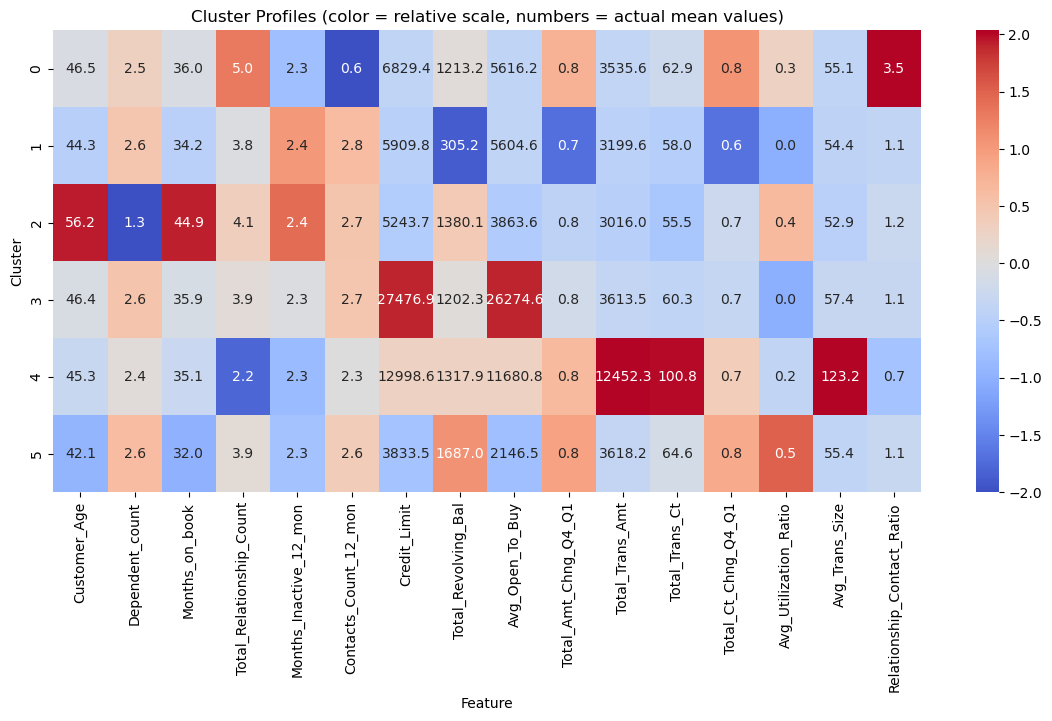

In [63]:
# Group by cluster on the original (unscaled) profiling data, same as before
cluster_means = original_df.groupby('Cluster')[feature_columns].mean()

# Standardize the means themselves so all features are visually comparable on the heatmap
cluster_means_scaled = (cluster_means - cluster_means.mean()) / cluster_means.std()

plt.figure(figsize=(14, 6))
sns.heatmap(cluster_means_scaled, annot=cluster_means.round(1), fmt='', cmap='coolwarm', center=0)
plt.title("Cluster Profiles (color = relative scale, numbers = actual mean values)")
plt.ylabel("Cluster")
plt.xlabel("Feature")
plt.show()

Principal Component analysis (PCA)

In [64]:
pca = PCA(n_components=2)
pca_result = pca.fit_transform(features)

pca_result

array([[-0.92467811, -1.11129883],
       [-1.18674112,  0.71832385],
       [-0.81340521,  1.09755193],
       ...,
       [ 2.55288566,  0.5928466 ],
       [ 1.96008776,  0.30171036],
       [ 2.40916264,  1.11133328]], shape=(10127, 2))

In [65]:
pca_df = pd.DataFrame(pca_result, columns=['pc1', 'pc2'], index=features.index)

pca_df['Cluster'] = Kmeans.labels_

In [66]:
pca_df.head()

,pc1,pc2,Cluster
0,-0.924678,-1.111299,5
1,-1.186741,0.718324,0
2,-0.813405,1.097552,0
3,-1.655688,2.524692,5
4,-2.173839,0.524519,0


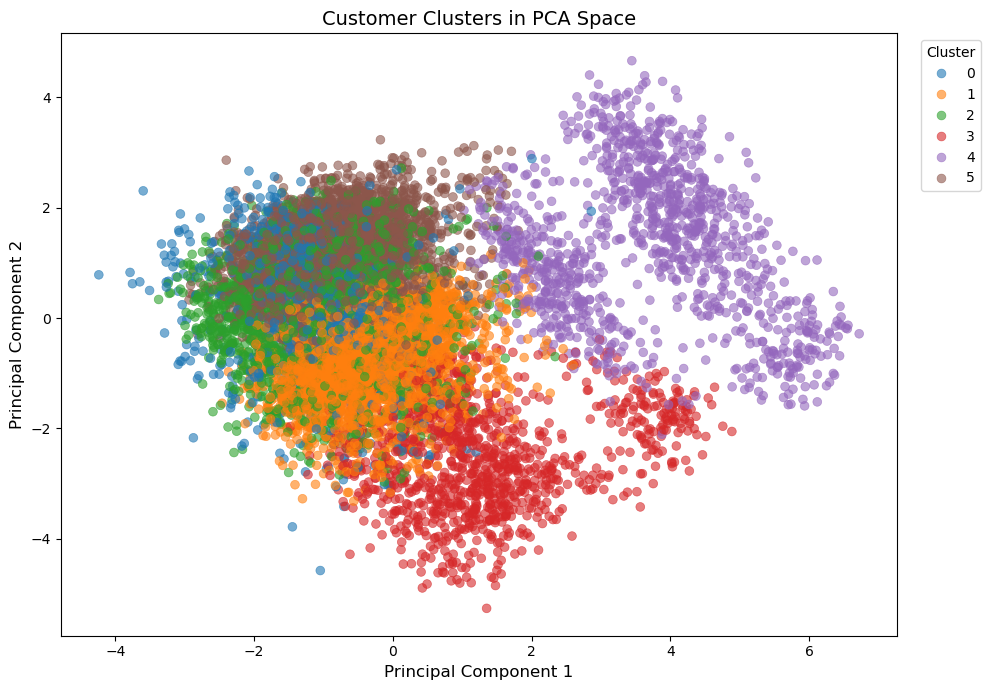

In [67]:
# Create the scatter plot
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x='pc1',
    y='pc2',
    hue='Cluster',
    palette='tab10',      # distinct colors for up to 10 clusters
    alpha=0.6,            # transparency to handle overlapping points
    s=40,                 # marker size
    edgecolor=None        # remove marker borders for a cleaner look
)

plt.title('Customer Clusters in PCA Space', fontsize=14)
plt.xlabel('Principal Component 1', fontsize=12)
plt.ylabel('Principal Component 2', fontsize=12)
plt.legend(title='Cluster', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [68]:
pca.explained_variance_ratio_

array([0.19206047, 0.14259482])

In [69]:
original_df['Cluster'].value_counts().sort_index()


Cluster
0     787
1    2451
2    1789
3    1189
4    1147
5    2764
Name: count, dtype: int64

 Part 3: Clustering Analysis

* Feature Selection for Clustering

Clustering was performed using K-Means on 16 continuous, scaled behavioral and demographic features (`Customer_Age`, `Dependent_count`, `Months_on_book`, `Total_Relationship_Count`, `Months_Inactive_12_mon`, `Contacts_Count_12_mon`, `Credit_Limit`, `Total_Revolving_Bal`, `Avg_Open_To_Buy`, `Total_Amt_Chng_Q4_Q1`, `Total_Trans_Amt`, `Total_Trans_Ct`, `Total_Ct_Chng_Q4_Q1`, `Avg_Utilization_Ratio`, `Avg_Trans_Size`, `Relationship_Contact_Ratio`). Encoded categorical columns (one-hot and ordinal) and the target variable (`Attrition_Flag`) were deliberately excluded from clustering.

K-Means relies on Euclidean distance, which assumes features share a comparable, meaningful numeric scale; one-hot encoded columns produce identical pairwise distances (√2) between any two categories regardless of how many categories exist or how different they conceptually are, distorting distance-based clustering. Categorical demographic features were instead reserved for interpreting and validating clusters after they were formed, rather than used to construct them.

* Choosing K: Elbow Method and Silhouette Score

K-Means was run for K = 2 through 10, recording inertia (within-cluster sum of squares) and silhouette score at each K.

**Inertia** decreased monotonically across all K, as expected, but the size of each successive drop shrank steadily: from a 14,346-point drop between K=2 and K=3, down to under 5,000 by K=6 and beyond. This indicates diminishing returns setting in around K=5–6.

**Silhouette score** peaked sharply at K=2 (0.224), then fell and plateaued in a narrow, mediocre band (0.11–0.13) for K=3 through K=10, with a minor local high point at K=7 (0.128).

**Final K = 6** was chosen by combining both signals. While silhouette score technically favors K=2, two clusters would not produce a business-useful segmentation for churn analysis. K=6 sits at the point where inertia's improvements have largely plateaued, and its silhouette score (0.124) is close to the local high point (K=7, 0.128) without adding unnecessary cluster complexity.

* Cluster Profiles

Cluster means were calculated on original, unscaled values (recovered via `scaler.inverse_transform()`) for interpretability. A heatmap of standardized cluster means visually confirmed each cluster's distinguishing traits.

| Cluster | Plain-English Name | Defining Traits |
|---|---|---|
| 0 | Product-engaged, low-contact customers | Highest relationship count (5.0), lowest contact count (0.6), highest relationship-to-contact ratio (3.5) |
| 1 | High-contact, low-credit-use customers | Lowest revolving balance (305) and utilization (0.05), highest contact count (2.8) |
| 2 | Matured, long-time customers | Oldest average age (56.2), longest tenure (44.9 months), fewest dependents (1.3) |
| 3 | High-limit conservative spenders | Highest credit limit (27,477) and open-to-buy (26,275), lowest utilization (0.047) |
| 4 | High-value transaction customers with low product engagement | Highest transaction amount (12,452), count (100.8), and average size (123), lowest relationship count (2.2) |
| 5 | Young, new, high-utilization customers | Youngest age (42.1), shortest tenure (32.0 months), highest utilization ratio (0.543) |

* PCA Visualization

Clusters were visualized in 2D using PCA on the same scaled feature set used for clustering. The two principal components captured only about **33.5%** of total variance (PC1: 19.2%, PC2: 14.3%), meaning the 2D plot is a simplified projection, not a full representation of the 16-dimensional clustering.

Consistent with this, clusters with the most extreme, distinctive profiles (**Cluster 4** and **Cluster 3**, both with unusually high values on specific features) appeared visually well-separated, while clusters distinguished by more subtle differences (**Clusters 0, 1, 2, and 5**) showed considerable overlap in the 2D projection. This overlap reflects a limitation of the visualization, not necessarily poor clustering, since K-Means operated on the full 16-dimensional feature space.

# PART 4 - CLASSIFICATION

In [70]:
print(df.dtypes)

CLIENTNUM                       int64
Attrition_Flag                 object
Customer_Age                  float64
Dependent_count               float64
Education_Level               float64
Income_Category               float64
Months_on_book                float64
Total_Relationship_Count      float64
Months_Inactive_12_mon        float64
Contacts_Count_12_mon         float64
Credit_Limit                  float64
Total_Revolving_Bal           float64
Avg_Open_To_Buy               float64
Total_Amt_Chng_Q4_Q1          float64
Total_Trans_Amt               float64
Total_Trans_Ct                float64
Total_Ct_Chng_Q4_Q1           float64
Avg_Utilization_Ratio         float64
Avg_Trans_Size                float64
Age_Group                     float64
Relationship_Contact_Ratio    float64
Gender_M                         bool
Marital_Status_Married           bool
Marital_Status_Single            bool
Marital_Status_Unknown           bool
Card_Category_Gold               bool
Card_Categor

In [71]:
# 2. Encode the target
df['Attrition_Flag'] = df['Attrition_Flag'].map({'Attrited Customer': 1, 'Existing Customer': 0})
df['Attrition_Flag'].value_counts()


Attrition_Flag
0    8500
1    1627
Name: count, dtype: int64

In [72]:
# Defining X and Separating features

X = df.drop(['Attrition_Flag', 'CLIENTNUM'], axis=1)
y = df['Attrition_Flag']

print(X.shape)
print(y.shape)

(10127, 26)
(10127,)


In [73]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)


print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

Shape of X_train: (8101, 26)
Shape of X_test: (2026, 26)
Shape of y_train: (8101,)
Shape of y_test: (2026,)
Attrition_Flag
0    0.839279
1    0.160721
Name: proportion, dtype: float64
Attrition_Flag
0    0.839585
1    0.160415
Name: proportion, dtype: float64


In [74]:
# Logistic Regression

log_reg_model = LogisticRegression(max_iter=1000, random_state=42)
log_reg_model.fit(X_train, y_train)

y_pred_logreg = log_reg_model.predict(X_test)

**Model 2: Decision Tree Classifier**

A Decision Tree Classifier was trained on the same training data (`X_train`, `y_train`), using default parameters (`max_depth=None`, `random_state=42` for reproducibility).

Leaving `max_depth` unrestricted allows the tree to grow until it fully separates the training data, which risks overfitting. This was accepted at this stage since hyperparameter tuning is outside the scope of this capstone, but is worth noting as a known limitation when interpreting results.

In [75]:
# Decision Trees

tree_model = DecisionTreeClassifier(max_depth=None, random_state=42)
tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)

**Model 3: Random Forest Classifier**

A Random Forest Classifier was trained on the same training data (`X_train`, `y_train`), using 100 trees (`n_estimators=100`, the default) and `random_state=42` for reproducibility.

As an ensemble method, Random Forest builds many individual decision trees, each on a random subset of data and features, and combines their predictions by majority vote. This directly addresses the overfitting risk noted for the single Decision Tree, generally producing more robust and generalizable predictions — at the cost of reduced interpretability compared to a single tree.

In [76]:
# Random Forest Classifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

Performance Measures for all three Models


*   Report Accuracy
*   Precision
*   recall
*   F1
*   ROC AUC
*   Confusion Matrix





**Logistic Regression**

In [77]:
precision_logreg = precision_score(y_test, y_pred_logreg)
accuracy_logreg = accuracy_score(y_test, y_pred_logreg)
recall_logreg = recall_score(y_test, y_pred_logreg)
f1_logreg = f1_score(y_test, y_pred_logreg)
confusion_logreg = confusion_matrix(y_test, y_pred_logreg)

y_proba_logreg = log_reg_model.predict_proba(X_test)[:, 1]
roc_auc_logreg = roc_auc_score(y_test, y_proba_logreg)

print("Precision (Logistic Regression):", precision_logreg)
print("Accuracy (Logistic Regression):", accuracy_logreg)
print("Recall (Logistic Regression):", recall_logreg)
print("F1 (Logistic Regression):", f1_logreg)
print("Confusion Matrix (Logistic Regression):\n", confusion_logreg)
print("ROC AUC (Logistic Regression):", roc_auc_logreg)

Precision (Logistic Regression): 0.8057851239669421
Accuracy (Logistic Regression): 0.9126357354392892
Recall (Logistic Regression): 0.6
F1 (Logistic Regression): 0.6878306878306878
Confusion Matrix (Logistic Regression):
 [[1654   47]
 [ 130  195]]
ROC AUC (Logistic Regression): 0.9309112286890064


**Decision Trees**

In [78]:
precision_tree_model = precision_score(y_test, y_pred_tree)
accuracy_tree_model = accuracy_score(y_test, y_pred_tree)
recall_tree_model = recall_score(y_test, y_pred_tree)
f1_tree_model = f1_score(y_test, y_pred_tree)
confusion_tree_model = confusion_matrix(y_test, y_pred_tree)

y_proba_tree_model = tree_model.predict_proba(X_test)[:, 1]
roc_auc_tree_model = roc_auc_score(y_test, y_proba_tree_model)

print("Precision (Decision Tree):", precision_tree_model)
print("Accuracy (Decision Tree):", accuracy_tree_model)
print("Recall (Decision Tree):", recall_tree_model)
print("F1 (Decision Tree):", f1_tree_model)
print("Confusion Matrix (Decision Tree):\n", confusion_tree_model)
print("ROC AUC (Decision Tree):", roc_auc_tree_model)

Precision (Decision Tree): 0.8042168674698795
Accuracy (Decision Tree): 0.93928923988154
Recall (Decision Tree): 0.8215384615384616
F1 (Decision Tree): 0.8127853881278538
Confusion Matrix (Decision Tree):
 [[1636   65]
 [  58  267]]
ROC AUC (Decision Tree): 0.8916628227739338


**Random Forest**

In [79]:
precision_rf_model = precision_score(y_test, y_pred_rf)
accuracy_rf_model = accuracy_score(y_test, y_pred_rf)
recall_rf_model = recall_score(y_test, y_pred_rf)
f1_rf_model = f1_score(y_test, y_pred_rf)
confusion_rf_model = confusion_matrix(y_test, y_pred_rf)

y_proba_rf_model = rf_model.predict_proba(X_test)[:, 1]
roc_auc_rf_model = roc_auc_score(y_test, y_proba_rf_model)

print("Precision (Random Forest):", precision_rf_model)
print("Accuracy (Random Forest):", accuracy_rf_model)
print("Recall (Random Forest):", recall_rf_model)
print("F1 (Random Forest):", f1_rf_model)
print("Confusion Matrix (Random Forest):\n", confusion_rf_model)
print("ROC AUC (Random Forest):", roc_auc_rf_model)


Precision (Random Forest): 0.9270833333333334
Accuracy (Random Forest): 0.9610069101678184
Recall (Random Forest): 0.8215384615384616
F1 (Random Forest): 0.8711256117455138
Confusion Matrix (Random Forest):
 [[1680   21]
 [  58  267]]
ROC AUC (Random Forest): 0.9885605752272419


**Model Justifications (Final, Results-Informed)**

 Logistic Regression

Chosen as a simple, interpretable baseline to establish what a linear model can achieve before testing more complex alternatives.

In practice, it produced the weakest recall (0.600) of the three, missing 130 of 325 actual churners, though it achieved a surprisingly strong ROC AUC (0.931), indicating the underlying relationship between features and churn is reasonably well captured even by a linear model — just not fully exploited at the default decision threshold.

 Decision Tree

Chosen for its ability to capture non-linear relationships and feature interactions that a linear model like Logistic Regression cannot, while remaining highly interpretable.

It substantially improved recall (0.822) and F1 (0.813) over Logistic Regression, at the cost of a lower ROC AUC (0.892), consistent with Decision Trees producing less smoothly calibrated probability estimates. Its known tendency to overfit (left unrestricted here, with `max_depth=None`) is a limitation worth noting, even though it performed well on this test set.

 Random Forest

Chosen as an ensemble method to address the Decision Tree's overfitting tendency by averaging predictions across many trees.

It delivered the best results across nearly every metric, including the highest accuracy (0.961), precision (0.927), F1 (0.871), and ROC AUC (0.989), while matching Decision Tree's recall (0.822). This aligns with the theoretical expectation that ensemble methods generalize better than a single tree, and makes Random Forest the strongest candidate of the three for this churn prediction task.

**Comparison Table**

In [80]:
comparison_table = pd.DataFrame({
    'Accuracy': [accuracy_logreg, accuracy_tree_model, accuracy_rf_model],
    'Precision': [precision_logreg, precision_tree_model, precision_rf_model],
    'Recall': [recall_logreg, recall_tree_model, recall_rf_model],
    'F1': [f1_logreg, f1_tree_model, f1_rf_model],
    'ROC AUC': [roc_auc_logreg, roc_auc_tree_model, roc_auc_rf_model]
}, index=['Logistic Regression', 'Decision Tree', 'Random Forest'])

comparison_table.round(3)

,Accuracy,Precision,Recall,F1,ROC AUC
Logistic Regression,0.913,0.806,0.600,0.688,0.931
Decision Tree,0.939,0.804,0.822,0.813,0.892
Random Forest,0.961,0.927,0.822,0.871,0.989


**Confusion Matrix Visualizations (All Three, Side by Side)**

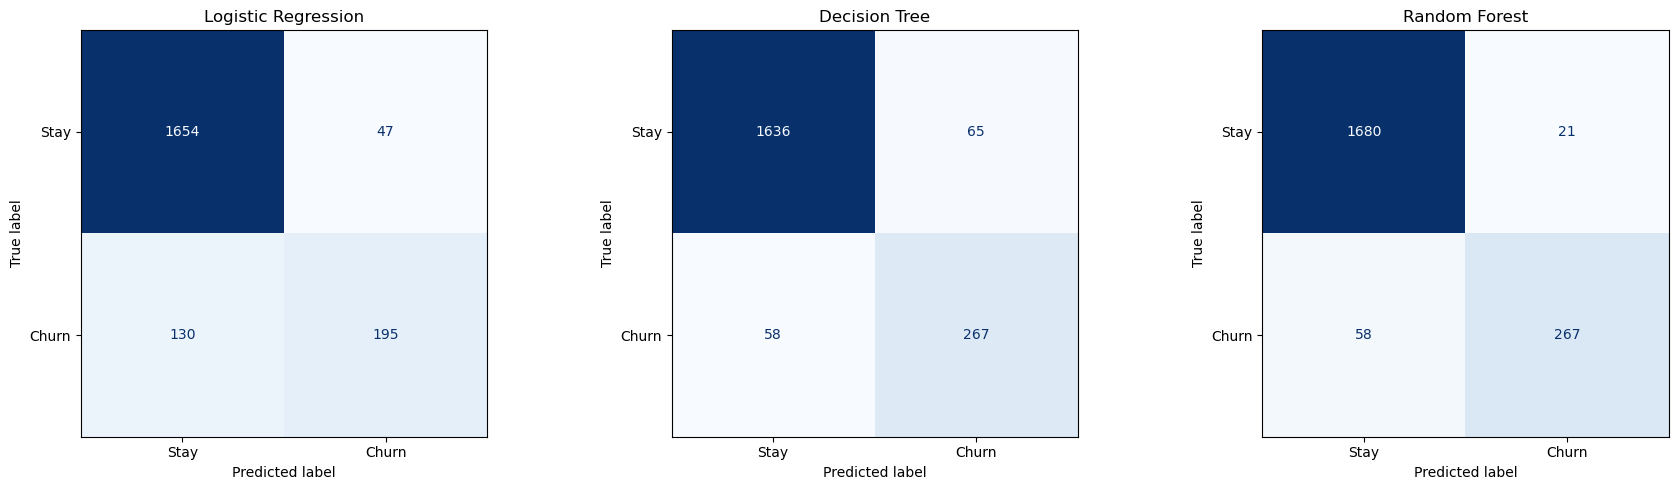

In [81]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

matrices = [
    (confusion_logreg, 'Logistic Regression'),
    (confusion_tree_model, 'Decision Tree'),
    (confusion_rf_model, 'Random Forest')
]

for ax, (cm, title) in zip(axes, matrices):
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Stay', 'Churn'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(title)

plt.tight_layout()
plt.show()

**Part 4 Summary**

Part 4: Classification

Target Preparation

`Attrition_Flag` was mapped from text labels to binary numeric values: **Attrited Customer = 1**, **Existing Customer = 0**. Attrited Customer was deliberately encoded as the positive class, since the business goal is identifying at-risk customers so the bank can intervene — meaning precision, recall, and F1 needed to be measured relative to correctly detecting churners.

During setup, a data pipeline issue was identified and corrected: three categorical columns (`Gender`, `Marital_Status`, `Card_Category`) had been one-hot encoded earlier into a separate variable that was never merged back into the working dataframe. This was resolved by re-applying `pd.get_dummies()` directly to the current dataframe, preserving all prior feature engineering and target encoding work.

 Train/Test Split

Data was split 80/20 into training and test sets using `train_test_split` with `stratify=y`, preserving the original ~84%/16% class balance in both sets (confirmed: train 83.9%/16.1%, test 83.96%/16.04%). A fixed `random_state=42` ensured reproducibility.

Since the dataset contains 10,127 rows — well above the 2,000-row threshold specified in the brief — a single stratified split was used rather than k-fold cross-validation. Features (`X`) consisted of all 26 columns except `Attrition_Flag` (target) and `CLIENTNUM` (identifier).

 Models Trained

Three classifiers covered in coursework were trained and compared:

- **Logistic Regression** — chosen as a simple, interpretable linear baseline (`max_iter=1000` to ensure convergence).
- **Decision Tree** — chosen for its ability to capture non-linear relationships and feature interactions while remaining interpretable (default parameters, `max_depth=None`).
- **Random Forest** — chosen as an ensemble method to reduce the overfitting risk inherent to a single Decision Tree by averaging predictions across many trees (`n_estimators=100`).

 Results

| Model | Accuracy | Precision | Recall | F1 | ROC AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.913 | 0.806 | 0.600 | 0.688 | 0.931 |
| Decision Tree | 0.939 | 0.804 | 0.822 | 0.813 | 0.892 |
| Random Forest | 0.961 | 0.927 | 0.822 | 0.871 | 0.989 |

**Logistic Regression** achieved the weakest recall (0.600), missing 130 of 325 actual churners in the test set, despite a strong ROC AUC (0.931) suggesting the model ranks customers by risk reasonably well overall — just not optimally at the default 0.5 threshold.

**Decision Tree** substantially improved recall (0.822) and F1 (0.813) over Logistic Regression, cutting missed churners to 58, while precision remained essentially unchanged (~80%). Its ROC AUC (0.892) was the lowest of the three, consistent with Decision Trees producing less smoothly calibrated probability estimates. Its unrestricted depth (`max_depth=None`) leaves it prone to overfitting — a limitation despite strong test-set performance here.

**Random Forest** outperformed both other models on every metric except recall, where it tied Decision Tree exactly (0.822, also missing 58 churners). It achieved the highest precision (0.927), fewest false alarms (21, versus 47 for Logistic Regression and 65 for Decision Tree), and near-perfect ROC AUC (0.989). This result aligns with the theoretical expectation that ensemble methods generalize better than a single decision tree, making Random Forest the strongest-performing model of the three for this churn prediction task.

 Business Interpretation

Given that missed churners (False Negatives) represent the costliest error for this business problem, Random Forest's combination of high recall (matching the best of the other models) and dramatically fewer false alarms (21 vs. up to 65) makes it the most practically useful model among the three tested — without requiring any hyperparameter tuning beyond default settings.

# PART 5 IMBALANCE HANDLING

In [82]:
# imbalance Handling for Logistic Regression

log_reg_model = LogisticRegression(max_iter=1000, random_state=42)
log_reg_model.fit(X_train, y_train)

y_pred_logreg = log_reg_model.predict(X_test)

In [83]:
# imbalance Handling for Logistic Regression (weighted)

log_reg_weighted = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
log_reg_weighted.fit(X_train, y_train)

y_pred_logreg_weighted = log_reg_weighted.predict(X_test)

In [84]:
precision_log_reg_weighted = precision_score(y_test, y_pred_logreg_weighted)
accuracy_log_reg_weighted = accuracy_score(y_test, y_pred_logreg_weighted)
recall_log_reg_weighted = recall_score(y_test, y_pred_logreg_weighted)
f1_log_reg_weighted = f1_score(y_test, y_pred_logreg_weighted)
confusion_log_reg_weighted = confusion_matrix(y_test, y_pred_logreg_weighted)

y_proba_log_reg_weighted = log_reg_weighted.predict_proba(X_test)[:, 1]
roc_auc_log_reg_weighted = roc_auc_score(y_test, y_proba_log_reg_weighted)

print("Precision (Logistic Regression - Weighted):", precision_log_reg_weighted)
print("Accuracy (Logistic Regression - Weighted):", accuracy_log_reg_weighted)
print("Recall (Logistic Regression - Weighted):", recall_log_reg_weighted)
print("F1 (Logistic Regression - Weighted):", f1_log_reg_weighted)
print("Confusion Matrix (Logistic Regression - Weighted):\n", confusion_log_reg_weighted)
print("ROC AUC (Logistic Regression - Weighted):", roc_auc_log_reg_weighted)

Precision (Logistic Regression - Weighted): 0.5599173553719008
Accuracy (Logistic Regression - Weighted): 0.868213228035538
Recall (Logistic Regression - Weighted): 0.8338461538461538
F1 (Logistic Regression - Weighted): 0.6699629171817059
Confusion Matrix (Logistic Regression - Weighted):
 [[1488  213]
 [  54  271]]
ROC AUC (Logistic Regression - Weighted): 0.9345941301496856


In [85]:
# Threshold Tuning

precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba_logreg)


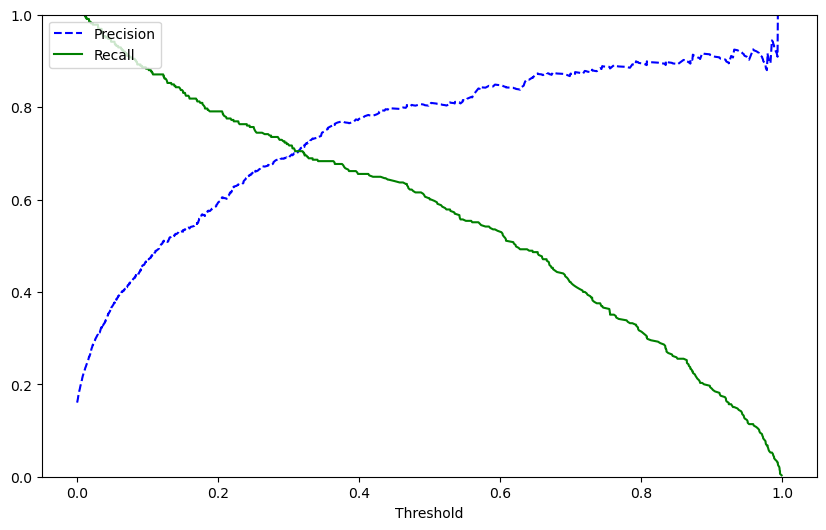

In [86]:
# threshold visualizations

plt.figure(figsize=(10, 6))
plt.plot(thresholds, precisions[:-1], "b--", label="Precision")
plt.plot(thresholds, recalls[:-1], "g-", label="Recall")
plt.xlabel("Threshold")
plt.legend(loc="upper left")
plt.ylim([0, 1])
plt.show()

In [87]:
idx = np.argmin(np.abs(thresholds - 0.25))

In [88]:
print("Best Threshold:", thresholds[idx])
print("Best Precision:", precisions[idx])
print("Best Recall:", recalls[idx])

Best Threshold: 0.25023643296314396
Best Precision: 0.6595174262734584
Best Recall: 0.7569230769230769


In [89]:
y_pred_logreg_030 = (y_proba_logreg >= 0.30).astype(int)

print("Precision:", precision_score(y_test, y_pred_logreg_030))
print("Accuracy:", accuracy_score(y_test, y_pred_logreg_030))
print("Recall:", recall_score(y_test, y_pred_logreg_030))
print("F1:", f1_score(y_test, y_pred_logreg_030))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_logreg_030))

Precision: 0.6913946587537092
Accuracy: 0.9032576505429417
Recall: 0.7169230769230769
F1: 0.7039274924471299
Confusion Matrix:
 [[1597  104]
 [  92  233]]


In [90]:
imbalance_comparison = pd.DataFrame({
    'Accuracy': [accuracy_logreg, accuracy_log_reg_weighted, accuracy_score(y_test, y_pred_logreg_030)],
    'Precision': [precision_logreg, precision_log_reg_weighted, precision_score(y_test, y_pred_logreg_030)],
    'Recall': [recall_logreg, recall_log_reg_weighted, recall_score(y_test, y_pred_logreg_030)],
    'F1': [f1_logreg, f1_log_reg_weighted, f1_score(y_test, y_pred_logreg_030)],
    'ROC AUC': [roc_auc_logreg, roc_auc_log_reg_weighted, roc_auc_logreg]  # threshold tuning doesn't change ROC AUC
}, index=['Baseline (0.50)', 'Class-Weighted', 'Threshold Tuned (0.30)'])

imbalance_comparison.round(3)

,Accuracy,Precision,Recall,F1,ROC AUC
Baseline (0.50),0.913,0.806,0.600,0.688,0.931
Class-Weighted,0.868,0.560,0.834,0.670,0.935
Threshold Tuned (0.30),0.903,0.691,0.717,0.704,0.931


**Part 5: Imbalance Handling Summary**

Two techniques were applied to address class imbalance (~84% Existing, ~16% Attrited): **class weights** and **threshold tuning**. Both were applied specifically to Logistic Regression, since it showed the clearest imbalance-related weakness among the three classifiers in Part 4, with the lowest recall (0.600) despite strong precision and ROC AUC. Decision Tree and Random Forest already achieved substantially higher recall (0.822) without intervention, so they were left out of scope for this section.

Technique 1: Class Weights

Logistic Regression was retrained with `class_weight='balanced'`, which automatically penalizes misclassifying the minority class (churners) more heavily during training. This shifted the model's behavior substantially:

- **Recall** rose from 0.600 → **0.834**
- **Precision** fell sharply from 0.806 → **0.560**
- **Accuracy** dropped from 0.913 → **0.868**
- **ROC AUC** remained essentially unchanged (0.931 → 0.935)

This confirms that class weighting does **not** improve the model's underlying ability to separate churners from non-churners; it only shifts where the default decision boundary sits — trading false alarms for caught churners.

Technique 2: Threshold Tuning

Using the baseline model's predicted probabilities, a precision-recall curve was plotted to visualize the trade-off across all possible decision thresholds. Business reasoning was used to select a threshold below the default 0.5:

- A **missed churner (False Negative)** represents a complete loss of the customer relationship with no chance for the bank to intervene.
- A **false alarm (False Positive)** represents a smaller, recoverable cost (an unnecessary retention offer).

This asymmetry justifies prioritizing recall over precision to some degree.

Three candidate thresholds were evaluated:

| Threshold | Precision | Recall |
|---|---|---|
| 0.50 (baseline) | 0.806 | 0.600 |
| 0.30 | 0.691 | 0.717 |
| 0.25 | 0.660 | 0.757 |

**Threshold 0.30 was selected as the final choice**, since it captured most of the achievable recall improvement (60.0% → 71.7%), while the further drop to 0.25 offered only marginal additional recall (+3.7 points) for a comparable additional cost in precision — reflecting diminishing returns.

Comparison

| Metric | Baseline (0.50) | Class-Weighted | Threshold Tuned (0.30) |
|---|---|---|---|
| Accuracy | 0.913 | 0.868 | 0.903 |
| Precision | 0.806 | 0.560 | 0.691 |
| Recall | 0.600 | 0.834 | 0.717 |
| F1 | 0.688 | 0.670 | **0.704** |
| ROC AUC | 0.931 | 0.935 | 0.931 |

**Conclusion**

Threshold tuning at 0.30 produced the best overall F1 score (0.704) of the three variants, improving recall meaningfully (60.0% → 71.7%) while retaining substantially higher precision and accuracy than class weighting.

Class weighting achieved the highest raw recall (0.834) but at a steep cost to precision and accuracy, representing a more extreme and less controllable trade-off. Threshold tuning offered a more deliberate, business-justified balance, informed directly by the precision-recall curve rather than an automatic rebalancing mechanism — making it the preferred technique of the two for this churn prediction problem, given the stated cost asymmetry between missed churners and false alarms.

# PART 6: The Tie-In

**Part 6: The Tie-In**

Positive-Class Rate by Cluster

| Cluster | Plain-English Name | Churn Rate |
|---|---|---|
| 0 | Product-engaged, low-contact customers | 2.67% |
| 1 | High-contact, low-credit-use customers | 33.62% |
| 2 | Matured, long-time customers | 13.47% |
| 3 | High-limit conservative spenders | 14.89% |
| 4 | High-value transaction customers with low product engagement | 11.86% |
| 5 | Young, new, high-utilization customers | 8.25% |

Overall baseline churn rate across the full dataset: **16.07%**.

Were Any Clusters Strong Predictors of the Label?

Yes. Two clusters showed dramatic deviation from the baseline churn rate, despite the clustering having been performed entirely without access to `Attrition_Flag`.

**Cluster 0** (Product-engaged, low-contact customers) showed a churn rate of just 2.67%, roughly six times lower than the baseline. This cluster was defined by the highest relationship count and lowest contact count of any group, supporting the earlier hypothesis that customers deeply embedded across multiple bank products, who rarely need to contact support, are the most retained segment.

**Cluster 1** (High-contact, low-credit-use customers) showed a churn rate of 33.62%, more than double the baseline and over twelve times higher than Cluster 0. This cluster was defined by the highest contact count and lowest revolving balance/utilization of any group, directly confirming the reasoning behind the engineered `Relationship_Contact_Ratio` feature: that frequent customer service contact, in a customer base dominated by standard retail card holders, more plausibly reflects friction or dissatisfaction than genuine engagement — and that this friction is strongly associated with actual churn.

What This Tells Us About the Data

The fact that unsupervised clustering, based purely on behavioral and demographic features with no access to the churn label, produced clusters with such widely varying churn rates (2.67% to 33.62%) indicates that meaningful, real structure exists in the data that is genuinely predictive of churn risk.

This validates both the engineered features (particularly `Relationship_Contact_Ratio` and `Total_Relationship_Count`) and the clustering approach itself: the behavioral segments are not arbitrary mathematical groupings, but represent genuinely different risk profiles.

Practically, this suggests the bank could use cluster membership itself as an early, interpretable signal for prioritizing retention efforts — particularly flagging customers resembling Cluster 1's profile (high contact, low credit utilization) for proactive outreach, well before a full classification model's probability score would be needed.

# PART 7 - CONCLUSION AND RECOMMENDATION



## Which model would you deploy, and why?

**Random Forest** is the model I would deploy.

While it also had the highest raw accuracy (0.961), accuracy alone is not the deciding factor given the class imbalance established earlier in this project — a model that predicted "no churn" for everyone would already score close to 84% without any real predictive value.

The stronger justification is that Random Forest:

- Achieved the best **precision** (0.927, well above Logistic Regression's 0.806 and Decision Tree's 0.804)
- Tied Decision Tree for the best **recall** (0.822)
- Posted a near-perfect **ROC AUC** (0.989)

Given the business framing established in Part 5 — that missed churners are the costliest error, but false alarms still carry a real cost in wasted retention spend — Random Forest is the only model that delivers strong recall (catching as many at-risk customers as the best alternative) without the steep precision trade-off seen in the class-weighted Logistic Regression variant (0.560 precision) or the plain Decision Tree (more false alarms at 65 versus Random Forest's 21).

Its near-perfect ROC AUC also means it would remain robust if the bank later wanted to adjust its own decision threshold to fit a different risk appetite, since the model separates the two classes well across virtually any cutoff, not just the default.

## What would you do with another month?

Three priorities stand out:

1. **Apply imbalance-handling techniques to Random Forest and Decision Tree directly** — class weights, threshold tuning, and ideally SMOTE — rather than only Logistic Regression. Since Random Forest is the deployment candidate, tuning its decision threshold specifically, the same way it was done for Logistic Regression in Part 5, could plausibly push its already-strong recall even higher with minimal precision cost.

2. **Revisit the ordinal encoding of `Education_Level` and `Income_Category`** — replacing the "Unknown at lowest rank" simplification with the flag-column approach discussed during this project, and empirically testing whether it improves validation performance, since the current approach knowingly introduces a small distortion.

3. **Investigate the drivers behind Cluster 1's high churn rate (33.6%) more directly** — ideally by obtaining actual "reason for contact" data from the bank, to confirm or refute the inference that high contact frequency reflects customer friction rather than engagement, since that inference was reasoned from indirect evidence, not confirmed directly.

## What did the clusters reveal that the classifier missed?

The clustering analysis surfaced a clean, human-interpretable customer segment — **Cluster 1, "high-contact, low-credit-use customers"** — with a **33.6% churn rate**, more than double the dataset's overall rate and over twelve times higher than the safest cluster (2.7%).

This is valuable in a way the classifier's output is not: a probability score from Random Forest tells you an individual customer's estimated churn risk, but it does not hand the business a describable, actionable group they can design a targeted intervention around without running the model at all.

The clustering also surfaced this pattern using only behavioral and demographic features, with no access to the churn label — a stronger form of validation than a classifier assigning high feature importance to the same variables, since it shows the structure exists independently in the data itself.

In short, the classifier is better at **scoring individuals**; the clustering was better at **explaining and packaging a segment** the business can act on directly.

## What was the hardest decision your team made?

The hardest decision was choosing the final number of clusters (**K=6**) when the elbow method and silhouette score pointed in different directions:

- **Silhouette score** peaked sharply at **K=2**
- **Elbow curve** suggested diminishing returns setting in around **K=5–6**

Taking the silhouette-optimal answer at face value would have produced a technically "better-separated" clustering that was too coarse to be useful for business segmentation, while ignoring it entirely would have meant discarding a real, strong signal.

Resolving this required judgment rather than a formula: prioritizing **business usefulness** over the single metric that scored best, while still using both signals together to land on a defensible middle ground rather than an arbitrary one.

# DEPTH TRACK

In [91]:

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)

precision_knn = precision_score(y_test, y_pred_knn)
accuracy_knn = accuracy_score(y_test, y_pred_knn)
recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)
confusion_knn = confusion_matrix(y_test, y_pred_knn)
y_proba_knn = knn_model.predict_proba(X_test)[:, 1]
roc_auc_knn = roc_auc_score(y_test, y_proba_knn)

print("Precision (KNN):", precision_knn)
print("Accuracy (KNN):", accuracy_knn)
print("Recall (KNN):", recall_knn)
print("F1 (KNN):", f1_knn)
print("Confusion Matrix (KNN):\n", confusion_knn)
print("ROC AUC (KNN):", roc_auc_knn)

Precision (KNN): 0.8268398268398268
Accuracy (KNN): 0.914116485686081
Recall (KNN): 0.5876923076923077
F1 (KNN): 0.6870503597122302
Confusion Matrix (KNN):
 [[1661   40]
 [ 134  191]]
ROC AUC (KNN): 0.9110586532808755


In [92]:
comparison_table = pd.DataFrame({
    'Accuracy': [accuracy_logreg, accuracy_tree_model, accuracy_rf_model, accuracy_knn],
    'Precision': [precision_logreg, precision_tree_model, precision_rf_model, precision_knn],
    'Recall': [recall_logreg, recall_tree_model, recall_rf_model, recall_knn],
    'F1': [f1_logreg, f1_tree_model, f1_rf_model, f1_knn],
    'ROC AUC': [roc_auc_logreg, roc_auc_tree_model, roc_auc_rf_model, roc_auc_knn]
}, index=['Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN'])

comparison_table.round(3)

,Accuracy,Precision,Recall,F1,ROC AUC
Logistic Regression,0.913,0.806,0.600,0.688,0.931
Decision Tree,0.939,0.804,0.822,0.813,0.892
Random Forest,0.961,0.927,0.822,0.871,0.989
KNN,0.914,0.827,0.588,0.687,0.911


**ROC CURVE OVERLAY**

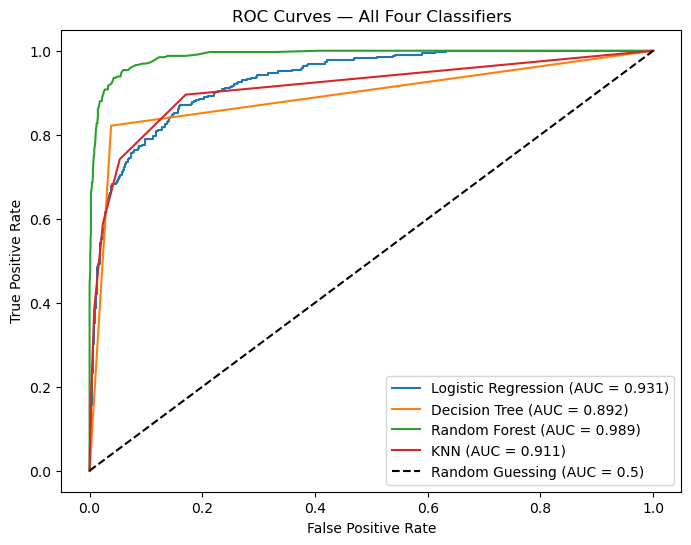

In [93]:
models_proba = {
    'Logistic Regression': (y_proba_logreg, roc_auc_logreg),
    'Decision Tree': (y_proba_tree_model, roc_auc_tree_model),
    'Random Forest': (y_proba_rf_model, roc_auc_rf_model),
    'KNN': (y_proba_knn, roc_auc_knn)
}

plt.figure(figsize=(8, 6))

for name, (proba, auc) in models_proba.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — All Four Classifiers')
plt.legend(loc='lower right')
plt.show()

**FEATURE IMPORTANCE**

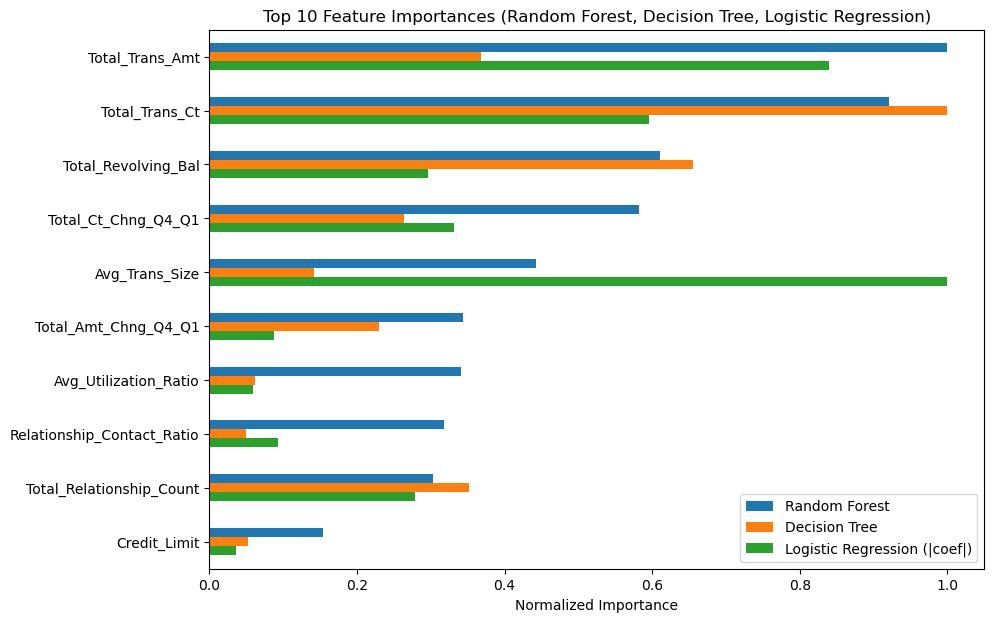

In [94]:
importance_df = pd.DataFrame({
    'Random Forest': rf_model.feature_importances_,
    'Decision Tree': tree_model.feature_importances_,
    'Logistic Regression (|coef|)': abs(log_reg_model.coef_[0])
}, index=X.columns)

# Normalize Logistic Regression coefficients to 0-1 scale for visual comparability
importance_df['Logistic Regression (|coef|)'] = (
    importance_df['Logistic Regression (|coef|)'] / importance_df['Logistic Regression (|coef|)'].max()
)
importance_df['Random Forest'] = importance_df['Random Forest'] / importance_df['Random Forest'].max()
importance_df['Decision Tree'] = importance_df['Decision Tree'] / importance_df['Decision Tree'].max()

importance_df.sort_values('Random Forest', ascending=False).head(10).plot(kind='barh', figsize=(10, 7))
plt.xlabel('Normalized Importance')
plt.title('Top 10 Feature Importances (Random Forest, Decision Tree, Logistic Regression)')
plt.gca().invert_yaxis()
plt.show()

**Depth Track: Classification Summary**

 Model Comparison

Four classifiers were compared: **Logistic Regression**, **Decision Tree**, **Random Forest**, and **KNN (K=5)**.

KNN performed similarly to Logistic Regression across most metrics:

| Model | Accuracy | Precision | Recall | F1 | ROC AUC |
|---|---|---|---|---|---|
| KNN (K=5) | 0.914 | 0.827 | 0.588 | 0.687 | 0.911 |
| Logistic Regression | 0.913 | 0.806 | 0.600 | 0.688 | 0.931 |

KNN shared the same core weakness of comparatively low recall, missing the second-highest number of churners (134) among the four models. This likely reflects KNN's sensitivity to distance calculations across a mixed feature space of scaled continuous variables and unscaled encoded categorical variables — a known limitation of distance-based methods noted earlier in this project when justifying feature selection for K-Means clustering.

**ROC Curve Analysis**

The ROC curve overlay confirms **Random Forest's dominance**, hugging the top-left corner across nearly the entire curve, consistent with its near-perfect ROC AUC (0.989).

- **Logistic Regression and KNN** — curves track each other closely throughout, consistent with their similar AUCs (0.931 vs 0.911).
- **Decision Tree** — notably the weakest curve of the four in the lower-threshold region, despite having the second-best F1 score at the default 0.5 threshold. This illustrates that its hard predictions at one specific cutoff are strong, but its probability calibration across the full range of thresholds is the roughest of the four models.

**Feature Importance Comparison**

Feature importance comparison across Random Forest, Decision Tree, and Logistic Regression (coefficients, normalized for comparability) showed general agreement on the most influential features:

- **`Total_Trans_Amt`** and **`Total_Trans_Ct`** — consistently ranked among the top predictors across all three models.
- **`Avg_Trans_Size`** — one of this project's engineered features, and the single highest-weighted predictor for Logistic Regression specifically.
- **`Relationship_Contact_Ratio`** — the other engineered feature, also showed meaningful importance across all three models.

This convergence across structurally different model types (a linear model, a single tree, and an ensemble) strengthens confidence that these variables,  including both engineered ratio features — reflect genuine, robust signal for predicting churn, rather than an artifact of any one algorithm's particular biases or a coincidence of the feature engineering process.

**Note:** KNN was excluded from this comparison, as it has no native feature importance measure — it stores training data directly rather than learning explicit weights or splits.

**Cross-Validation**

In [95]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models_cv = {
    'Logistic Regression': log_reg_model,
    'Decision Tree': tree_model,
    'Random Forest': rf_model,
    'KNN': knn_model
}

cv_results = {}

for name, model in models_cv.items():
    f1_scores = cross_val_score(model, X, y, cv=cv, scoring='f1')
    auc_scores = cross_val_score(model, X, y, cv=cv, scoring='roc_auc')
    cv_results[name] = {
        'F1 Mean': f1_scores.mean(),
        'F1 Std': f1_scores.std(),
        'ROC AUC Mean': auc_scores.mean(),
        'ROC AUC Std': auc_scores.std()
    }

cv_comparison = pd.DataFrame(cv_results).T
cv_comparison.round(3)

,F1 Mean,F1 Std,ROC AUC Mean,ROC AUC Std
Logistic Regression,0.699,0.024,0.935,0.004
Decision Tree,0.805,0.021,0.883,0.014
Random Forest,0.883,0.011,0.990,0.002
KNN,0.694,0.018,0.915,0.013


**Dummy Classifier**

In [96]:
dummy_model = DummyClassifier(strategy='stratified', random_state=42)

dummy_f1 = cross_val_score(dummy_model, X, y, cv=cv, scoring='f1')
dummy_auc = cross_val_score(dummy_model, X, y, cv=cv, scoring='roc_auc')

print("Dummy F1 Mean:", dummy_f1.mean(), "Std:", dummy_f1.std())
print("Dummy ROC AUC Mean:", dummy_auc.mean(), "Std:", dummy_auc.std())

Dummy F1 Mean: 0.16381819455143914 Std: 0.030977879587326805
Dummy ROC AUC Mean: 0.5013643227937707 Std: 0.0185620391293369


**Cross-Validation**

To validate that the single train/test split results were not an artifact of one particular data split, all four classifiers (Logistic Regression, Decision Tree, Random Forest, KNN) were re-evaluated using **5-fold stratified cross-validation** on the full dataset, reporting the mean and standard deviation of F1 and ROC AUC across folds.

| Model | F1 Mean | F1 Std | ROC AUC Mean | ROC AUC Std |
|---|---|---|---|---|
| Logistic Regression | 0.699 | 0.024 | 0.935 | 0.004 |
| Decision Tree | 0.805 | 0.021 | 0.883 | 0.014 |
| Random Forest | 0.883 | 0.011 | 0.990 | 0.002 |
| KNN | 0.694 | 0.018 | 0.915 | 0.013 |

These results closely mirror the original single-split evaluation (Random Forest F1 0.871 → 0.883, ROC AUC 0.989 → 0.990), confirming the earlier findings generalize rather than reflecting a favorable split.

Random Forest additionally showed the **lowest variance of any model** across both metrics (F1 std 0.011, ROC AUC std 0.002), indicating it is not only the strongest performer on average but also the most stable and reliable across different subsets of the data — further supporting its selection as the model to deploy.

**Dummy Classifier Baseline**

A `DummyClassifier` using a stratified random guessing strategy (predicting churn/stay according to the training data's class proportions, with no use of any feature) was evaluated with the same 5-fold cross-validation setup, to establish a performance floor.

| Metric | Mean | Std |
|---|---|---|
| F1 | 0.164 | 0.031 |
| ROC AUC | 0.501 | 0.019 |

The dummy baseline's ROC AUC of 0.501 confirms it performs no better than random chance, as expected. Comparing this against Random Forest's cross-validated F1 (0.883) and ROC AUC (0.990) demonstrates that the final model's performance reflects **genuine, learned predictive signal** in the data, not an artifact of exploiting class imbalance alone.

**Leakage Investigation**

In [97]:
# Test for potential leakage: retrain without the two highest-importance features
X_no_trans = X.drop(['Total_Trans_Amt', 'Total_Trans_Ct'], axis=1)

X_train_nt, X_test_nt, y_train_nt, y_test_nt = train_test_split(
    X_no_trans, y, test_size=0.2, random_state=42, stratify=y
)

rf_model_notrans = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model_notrans.fit(X_train_nt, y_train_nt)

y_proba_notrans = rf_model_notrans.predict_proba(X_test_nt)[:, 1]
y_pred_notrans = rf_model_notrans.predict(X_test_nt)

print("ROC AUC without Total_Trans_Amt/Total_Trans_Ct:", roc_auc_score(y_test_nt, y_proba_notrans))
print("F1 without Total_Trans_Amt/Total_Trans_Ct:", f1_score(y_test_nt, y_pred_notrans))

ROC AUC without Total_Trans_Amt/Total_Trans_Ct: 0.9181214670103559
F1 without Total_Trans_Amt/Total_Trans_Ct: 0.6641509433962264


**Leakage Investigation**

Given the near-perfect ROC AUC (0.989) achieved by Random Forest, potential leakage was investigated by retraining the model without its two highest-importance features, `Total_Trans_Amt` and `Total_Trans_Ct`.

| Metric | Full Model | Without Top 2 Features |
|---|---|---|
| ROC AUC | 0.989 | 0.918 |
| F1 | 0.871 | 0.664 |

ROC AUC declined from 0.989 to 0.918, and F1 declined from 0.871 to 0.664 — a **real but moderate drop**, not a collapse to near-random performance.

This pattern is consistent with these two features being genuinely strong, high-value predictors rather than leaking the target label itself; had leakage been present, removing the leaking column would typically cause a much sharper drop toward baseline performance.

No columns were identified as leaking the target and none were removed on this basis, beyond the two Naive Bayes classifier output columns already dropped during initial cleaning, which the dataset's own documentation explicitly flags as artifacts to discard.

In [98]:
notebook_end = time.time()
elapsed = notebook_end - notebook_start
print(f"Total notebook runtime: {elapsed/60:.2f} minutes")


Total notebook runtime: 1.54 minutes
